# Task 1 — Push-T Diffusion Policy implementation
**Asya Ünal**

setup, dataset inspection, simulator, networks, DDPM, training,
Table I-style summaries, Figure 7-style learning curves, restricted Figure 6-style
ablations, and five seeded environments for each architecture.

Run cells in order with `MODE='train'`. `MODE='smoke'` performs a separate, small integration
test; its scores are not experiment results. `MODE='evaluate'` uses this experiment's own
saved weights. Checkpoints resume automatically; raw-five weights are incompatible.

I used 1,000 epochs, 10 evaluation episodes due to limited compute and seeds
42/43/44. Original paper uses 4,500-epoch and 50-episode protocol.

The saved tables, plots and rollout visualizations can be read without running code. To reproduce the experiment, execute the notebook in order with its dataset and GPU setup. 


## Completed execution — 12 October 2026

This notebook contains the saved outputs of six fresh RTX 5090 training runs: DP-C and DP-T, seeds 42/43/44, 1,000 epochs each, 20 keypoint/pusher observations, prediction horizon 16, and 100 DDPM steps. The data tables and plots below are actual saved outputs.


## 1. Sources, experimental choices, and required outputs
Reference: [paper v4](https://arxiv.org/html/2303.04137v4),
[website](https://diffusion-policy.cs.columbia.edu/), and repository commit
`5ba07ac6661db573af695b419a7947ecb704690f`.

I followed the paper-specific settings.
CNN widths follow the released state implementation. 
I could not locate the complete training configuration used for Figure 6. I therefore retained the 16-step prediction horizon from the released baseline configuration and evaluated execution horizons of 1, 2, 4, 8 and 15 actions.

[Dataset](https://github.com/real-stanford/diffusion_policy/blob/5ba07ac6661db573af695b419a7947ecb704690f/diffusion_policy/dataset/pusht_dataset.py),
[CNN configuration](https://diffusion-policy.cs.columbia.edu/data/experiments/low_dim/pusht/diffusion_policy_cnn/config.yaml),
[Transformer configuration](https://github.com/real-stanford/diffusion_policy/blob/5ba07ac6661db573af695b419a7947ecb704690f/diffusion_policy/config/train_diffusion_transformer_lowdim_pusht_workspace.yaml),
[CNN delay compensation](https://github.com/real-stanford/diffusion_policy/blob/5ba07ac6661db573af695b419a7947ecb704690f/diffusion_policy/config/train_diffusion_unet_lowdim_workspace.yaml).


## 2. Install simulation and dataset readers
These packages support simulation, data decoding and notebook display; no external learning implementation is imported. I used Google Drive for storage so in the code there are lines to setup Drive as storage for Colab. 

In [ ]:
%pip install numpy matplotlib ipython 'gymnasium>=1,<2' 'pygame>=2.6,<3' 'pymunk>=6.11,<7' 'shapely>=2,<3' 'opencv-python-headless>=4.10' 'scikit-image>=0.25' 'zarr>=2.18,<3' 'numcodecs>=0.15,<0.16'


## 3. Imports, persistent storage, and approved run controls

In [ ]:
# Learning: PyTorch + NumPy. 
# Presentation: Matplotlib + standard notebook display.
# Zarr/numcodecs ONLY read data.

import os, sys, math, time, json, csv, copy, random, hashlib, zipfile, tempfile, html
from pathlib import Path
from importlib import metadata
from collections import deque
from contextlib import contextmanager
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import display, HTML
from IPython import get_ipython
if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")

os.environ.setdefault('SDL_VIDEODRIVER', 'dummy')
os.environ.setdefault('SDL_AUDIODRIVER', 'dummy')

# Choose persistent storage. LIRA_PROJECT_ROOT overrides the platform default.
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB and not os.environ.get('LIRA_PROJECT_ROOT'):
    from google.colab import drive
    drive.mount('/content/drive')
    default_project = Path('/content/drive/MyDrive/lira_task1')
else:
    default_project = Path('/workspace/lira_task1') if Path('/workspace').is_dir() else Path.cwd()/'lira_task1'

PROJECT = Path(os.environ.get('LIRA_PROJECT_ROOT', str(default_project)))
DATA_DIR = PROJECT/'data'
EXPERIMENT = 'keypoints20_Tp16_1000ep_eval10_v1'  # Preserve previous experiments separately.
MODE = os.environ.get('LIRA_MODE', 'train')  # 'smoke', 'train', or 'evaluate'.
TRAIN_SEEDS = [42, 43, 44] 
HORIZONS = [16]
OBS_DIM = 20
OBS_HORIZON = 2
BASE_ACTION_HORIZON = 8
LATENCY_PROTOCOL = 'stale_obs_skip_delay_execute_fixed_Ta_v1'
TRAIN_EPOCHS = 1000
EVALUATION_EPISODES = 10
ROLLOUT_EVERY = 50
assert TRAIN_EPOCHS // ROLLOUT_EVERY >= 10, 'The last-ten summary needs ten evaluated checkpoints.'
SAVE_EVERY_UPDATES = 200
EVAL_BATCH_SIZE = 10  

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

RUN_DIR = PROJECT/'checkpoints'/EXPERIMENT/MODE.replace('evaluate','train')
RESULT_DIR = PROJECT/'results'/EXPERIMENT/('smoke' if MODE=='smoke' else 'submission')

for p in (DATA_DIR, RUN_DIR, RESULT_DIR):
    p.mkdir(parents=True, exist_ok=True)

if MODE not in ('smoke', 'train', 'evaluate'):
    raise ValueError(MODE)

# Set by the notebook build; checkpoints reject changes to the learning implementation.
IMPLEMENTATION_ID = '0c87bd8b154d93991ad49ccdd42d6668326d166fbdeabd5d77a28b591c5fbc0f'


def seed_all(seed):

    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

    if torch.cuda.is_available():
        torch.backends.cuda.matmul.allow_tf32 = False
        torch.backends.cudnn.allow_tf32 = False


def atomic_json(value, path):

    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temp = path.with_suffix('.writing')
    temp.write_text(json.dumps(value, indent=2, allow_nan=False))
    temp.replace(path)


def save_csv(rows, path):

    if not rows:
        return
    
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    fields = list(dict.fromkeys(k for r in rows for k in r))

    with path.open('w', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=fields)
        writer.writeheader(); writer.writerows(rows)


def display_table(rows):
    
    """Print a table that also remains visible in restricted notebook viewers."""
    if not rows:
        print('No results yet.')
        return
    fields = list(rows[0])
    table = [[str(field) for field in fields]]
    table += [[str(row.get(field, '')) for field in fields] for row in rows]
    widths = [max(len(row[i]) for row in table) for i in range(len(fields))]
    for index, row in enumerate(table):
        print(' | '.join(value.ljust(width) for value, width in zip(row, widths)))
        if index == 0:
            print('-+-'.join('-' * width for width in widths))


seed_all(42)
print('Python:',sys.version.split()[0], 'PyTorch:',torch.__version__, 'NumPy:',np.__version__)
print('Device:',DEVICE, torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else '')
if DEVICE.type=='cuda':
    print('Visible GPU memory (GiB):',torch.cuda.get_device_properties(0).total_memory/2**30)
print('Mode:',MODE,'\nCheckpoints:',RUN_DIR,'\nResults:',RESULT_DIR)
print(f'Reduced-budget runs: {TRAIN_EPOCHS} epochs, {EVALUATION_EPISODES} evaluation episodes, seeds {TRAIN_SEEDS}. Keypoint observations; Tp=16 only.')
package_versions={}
for package in ['torch','numpy','matplotlib','gymnasium','pymunk','pygame','shapely','opencv-python-headless','scikit-image','zarr','numcodecs']:
    try: package_versions[package]=metadata.version(package)
    except metadata.PackageNotFoundError: package_versions[package]='unavailable'
atomic_json({'packages':package_versions,'python':sys.version, 'numpy':np.__version__, 'torch':torch.__version__,
             'gpu':torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else None,
             'implementation':IMPLEMENTATION_ID, 'mode':MODE, 'training_epochs':TRAIN_EPOCHS,
             'observation': 'keypoint18_then_pusher2', 'latency_protocol': LATENCY_PROTOCOL,
             'evaluation_episodes':EVALUATION_EPISODES, 'training_seeds':TRAIN_SEEDS, 'horizons':HORIZONS}, RESULT_DIR/'runtime.json')

Python: 3.12.3 PyTorch: 2.11.0+cu130 NumPy: 2.1.3
Device: cuda NVIDIA GeForce RTX 5090
Visible GPU memory (GiB): 31.356689453125
Mode: train 
Checkpoints: /workspace/keypoint_project/checkpoints/keypoints20_Tp16_1000ep_eval10_v1/train 
Results: /workspace/keypoint_project/results/keypoints20_Tp16_1000ep_eval10_v1/submission
Reduced-budget runs: 1000 epochs, 10 evaluation episodes, seeds [42, 43, 44]. Keypoint observations; Tp=16 only.


## 4. Dataset inspection and visual validation
Reads every array's metadata without loading all images into memory. Tables show shapes,
types, coordinate ranges, episode lengths and representative policy input rows. Plots show
where demonstrations cover the desk and how states and target actions evolve.

array             | shape              | dtype   | meaning                               
------------------+--------------------+---------+---------------------------------------
data/action       | (25650, 2)         | float32 | target pusher x/y                     
data/img          | (25650, 96, 96, 3) | float32 | RGB image (not used as policy input)  
data/keypoint     | (25650, 9, 2)      | float32 | 9 block keypoints (policy input)      
data/n_contacts   | (25650, 1)         | float32 | contact count                         
data/state        | (25650, 5)         | float32 | pusher x/y, block x/y, angle (radians)
meta/episode_ends | (206,)             | int64   | exclusive demonstration end indices   
206 demonstrations; 25650 timesteps. Length min/median/max: 49/122/246
All state/action entries are finite; episode boundaries and action bounds passed.
coordinate | minimum                | maximum           
-----------+------------------------+-------------------
pusher x   | 

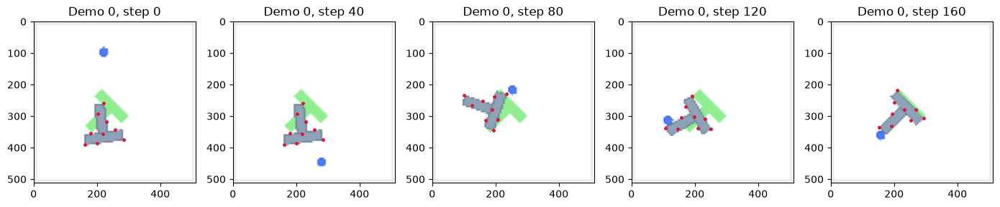

Policy observation: (25650, 20) ; maximum keypoint reconstruction error: 2.0516446463043962 pixels


In [ ]:
import zarr 
zip_path = DATA_DIR/'pusht.zip'

if not zip_path.exists():
    alternatives = [Path('/content/pusht.zip'), Path.home()/'Downloads/pusht.zip']
    zip_path = next((p for p in alternatives if p.exists()), zip_path)

if not zip_path.exists():
    raise FileNotFoundError(f'Upload pusht.zip to {DATA_DIR} and rerun.')

def file_digest(path):

    h = hashlib.sha256()

    with path.open('rb') as f:

        for piece in iter(lambda:f.read(8*1024*1024),b''):
            h.update(piece)

    return h.hexdigest()

archive_sha = file_digest(zip_path)
extraction = Path('/content/pusht_readonly') if IN_COLAB else Path(tempfile.gettempdir())/'lira_reimplementation_data'
marker = extraction/'.complete_sha256'

if not marker.exists() or marker.read_text()!=archive_sha:

    extraction.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path) as archive:

        for item in archive.infolist():

            if not (extraction/item.filename).resolve().is_relative_to(extraction.resolve()):
                raise ValueError('Unsafe archive path')
            
        archive.extractall(extraction)

    marker.write_text(archive_sha)

root = zarr.open_group(str(extraction/'pusht/pusht_cchi_v7_replay.zarr'), mode='r')
states = root['data/state'][:].astype(np.float32)
actions = root['data/action'][:].astype(np.float32)
episode_ends = root['meta/episode_ends'][:].astype(np.int64)

assert states.shape == (len(actions),5) and actions.shape[1:] == (2,)
assert np.isfinite(states).all() and np.isfinite(actions).all()
assert episode_ends.ndim==1 and np.all(np.diff(np.r_[0,episode_ends])>0)
assert episode_ends[-1]==len(actions)
assert np.all((actions>=0)&(actions<=512))

episode_starts = np.r_[0,episode_ends[:-1]]

DATA_FINGERPRINT = hashlib.sha256(states.tobytes()+actions.tobytes()+episode_ends.tobytes()).hexdigest()

array_rows=[]

meanings={'state':'pusher x/y, block x/y, angle (radians)', 'action':'target pusher x/y',
          'img':'RGB image (not used as policy input)', 'keypoint':'9 block keypoints (policy input)',
          'episode_ends':'exclusive demonstration end indices', 'n_contacts':'contact count'}

def inspect_array(name, obj):

    if isinstance(obj,zarr.Array):

        array_rows.append({'array':name, 'shape':str(obj.shape), 'dtype':str(obj.dtype),
                           'meaning':meanings.get(name.split('/')[-1],'auxiliary data')})
        
root.visititems(inspect_array)
display_table(array_rows)
save_csv(array_rows, RESULT_DIR/'dataset_arrays.csv')
lengths=episode_ends-episode_starts

print(f'{len(lengths)} demonstrations; {len(actions)} timesteps. Length min/median/max: '
      f'{lengths.min()}/{np.median(lengths):g}/{lengths.max()}')

print('All state/action entries are finite; episode boundaries and action bounds passed.')

atomic_json({'archive_sha256':archive_sha,'learning_data_sha256':DATA_FINGERPRINT,
             'episodes':len(lengths),'timesteps':len(actions)}, RESULT_DIR/'dataset_identity.json')

display_table([{'coordinate':name,'minimum':float(states[:,i].min()),'maximum':float(states[:,i].max())}
               for i,name in enumerate(['pusher x','pusher y','block x','block y','angle'])])

episode=0
start,end=int(episode_starts[episode]),int(episode_ends[episode])
fig,axes=plt.subplots(1,5,figsize=(14,3))

for ax,frame in zip(axes,np.linspace(start,end-1,5,dtype=int)):

    image=np.asarray(root['data/img'][int(frame)])
    ax.imshow(np.clip(image,0,255).astype(np.uint8),extent=(0,512,512,0))
    keypoints=root['data/keypoint'][int(frame)]
    ax.scatter(keypoints[:,0],keypoints[:,1],s=6,color='crimson')
    ax.set_title(f'Demo {episode}, step {frame-start}');ax.set_aspect('equal')

fig.tight_layout();fig.savefig(RESULT_DIR/'demonstration.png',dpi=160);plt.show()

physical_states = states
block_keypoints = np.asarray(root['data/keypoint'][:], dtype=np.float32)

assert block_keypoints.shape == (len(actions), 9, 2)
assert np.isfinite(block_keypoints).all()
states = np.concatenate((block_keypoints.reshape(len(actions), 18), physical_states[:, :2]), axis=1)

OBS_NAMES = [f'keypoint_{i}_{axis}' for i in range(9) for axis in ['x','y']] + ['pusher_x','pusher_y']
DATA_FINGERPRINT = hashlib.sha256(states.tobytes()+actions.tobytes()+episode_ends.tobytes()).hexdigest()

atomic_json({'archive_sha256':archive_sha,'learning_data_sha256':DATA_FINGERPRINT,
             'observation_order':OBS_NAMES,'episodes':len(lengths),'timesteps':len(actions)},
             RESULT_DIR/'dataset_identity.json')

a = float(physical_states[0,4]); c, sn = np.cos(a), np.sin(a)
rot = np.array([[c,-sn],[sn,c]])

LOCAL_BLOCK_KEYPOINTS = (block_keypoints[0].astype(np.float64)-physical_states[0,2:4]) @ rot
angles = physical_states[:,4].astype(np.float64)
rotations = np.stack([np.cos(angles),-np.sin(angles),np.sin(angles),np.cos(angles)],axis=-1).reshape(-1,2,2)
reconstructed = np.einsum('nij,kj->nki', rotations, LOCAL_BLOCK_KEYPOINTS) + physical_states[:,None,2:4]
geometry_error = float(np.abs(reconstructed-block_keypoints).max())
geometry_errors = np.max(np.abs(reconstructed-block_keypoints), axis=(1,2))
assert np.median(geometry_errors) < .001, 'Keypoint ordering/geometry mismatch'
geometry_outliers = np.flatnonzero(geometry_errors > .01)

atomic_json({'max_error_pixels':geometry_error,'median_error_pixels':float(np.median(geometry_errors)),
             'frames_over_0_01_pixels':geometry_outliers.tolist(),
             'note':'Recorded arrays retained unchanged; occasional state/keypoint discrepancies are disclosed.'},
             RESULT_DIR/'keypoint_geometry_audit.json')

np.save(RESULT_DIR/'local_block_keypoints.npy',LOCAL_BLOCK_KEYPOINTS)
print('Policy observation:',states.shape,'; maximum keypoint reconstruction error:',geometry_error,'pixels')



POLICY OBSERVATIONS: 20 coordinates per timestep
coordinate   | minimum  | maximum  | mean     | std      | finite
-------------+----------+----------+----------+----------+-------
keypoint_0_x | 45.2941  | 444.741  | 213.8148 | 69.4115  | True  
keypoint_0_y | 100.4148 | 485.7815 | 318.3546 | 62.8332  | True  
keypoint_1_x | 21.6708  | 462.0999 | 218.4155 | 72.0645  | True  
keypoint_1_y | 69.7406  | 519.6061 | 246.7298 | 77.497   | True  
keypoint_2_x | 44.8819  | 465.1421 | 275.6049 | 72.1618  | True  
keypoint_2_y | 81.3858  | 509.7257 | 296.7557 | 71.4943  | True  
keypoint_3_x | 78.5818  | 414.4032 | 235.8662 | 61.4714  | True  
keypoint_3_y | 132.8599 | 461.7653 | 284.2168 | 61.1437  | True  
keypoint_4_x | 12.2014  | 468.9632 | 189.4064 | 81.3035  | True  
keypoint_4_y | 67.2305  | 521.0679 | 324.1135 | 70.613   | True  
keypoint_5_x | 79.0167  | 436.9777 | 251.2571 | 64.1558  | True  
keypoint_5_y | 114.1528 | 477.0761 | 303.7919 | 62.7198  | True  
keypoint_6_x | 61.4762  | 

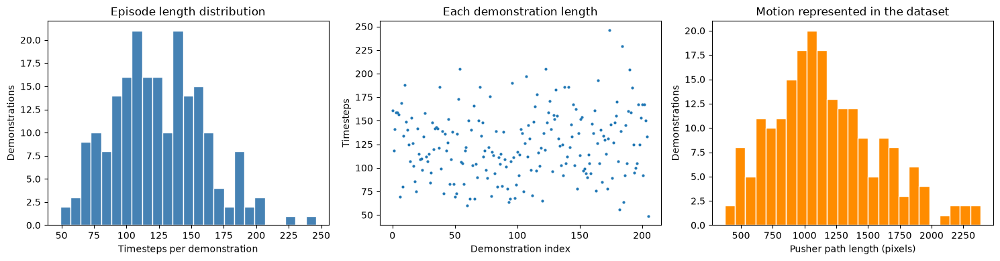

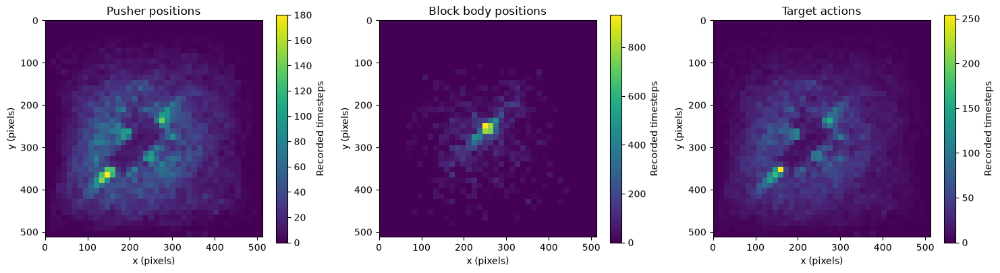

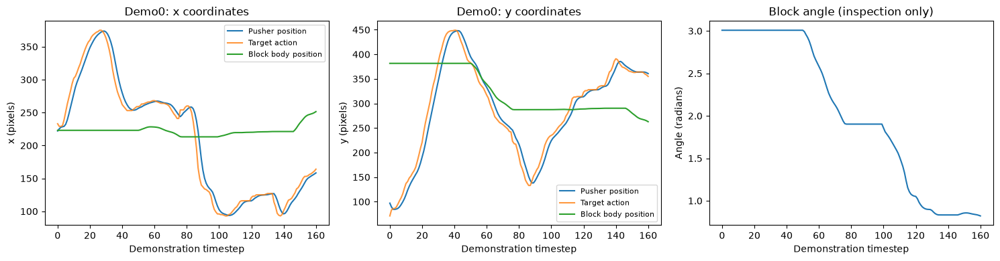

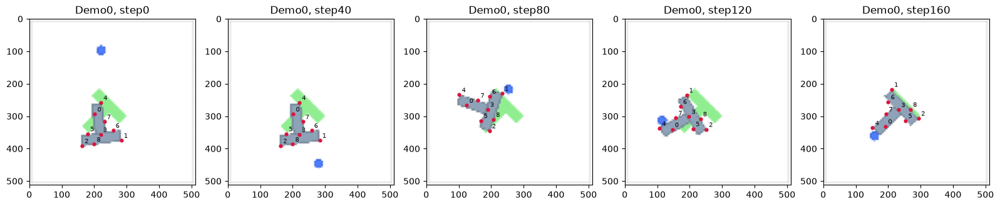

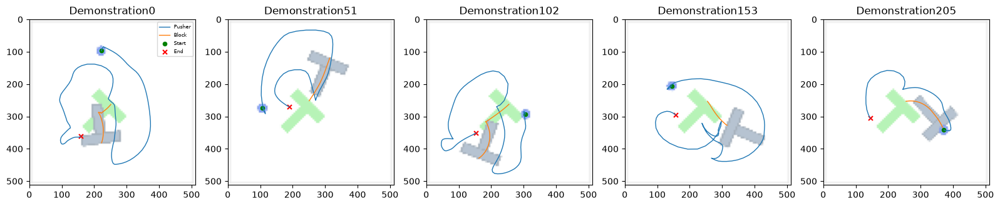

Dataset figures describe demonstrations; they are not policy-generated results.


In [ ]:
def numeric_summary(values, names):

    return [{'coordinate':name,'minimum':round(float(values[:,i].min()),4),
             'maximum':round(float(values[:,i].max()),4),
             'mean':round(float(values[:,i].mean()),4),
             'std':round(float(values[:,i].std()),4),
             'finite':bool(np.isfinite(values[:,i]).all())}
            for i,name in enumerate(names)]

print('\nPOLICY OBSERVATIONS: 20 coordinates per timestep')
observation_rows=numeric_summary(states,OBS_NAMES)
display_table(observation_rows);save_csv(observation_rows,RESULT_DIR/'observation_statistics.csv')
print('\nACTIONS: target positions, not displacements')
action_rows=numeric_summary(actions,['target_x','target_y'])
display_table(action_rows);save_csv(action_rows,RESULT_DIR/'action_statistics.csv')

episode_rows=[]

for ep,(lo,hi) in enumerate(zip(episode_starts,episode_ends)):
    lo,hi=int(lo),int(hi)
    episode_rows.append({'demonstration':ep,'first_index':lo,'end_exclusive':hi,'timesteps':hi-lo,
                        'pusher_path_pixels':round(float(np.linalg.norm(np.diff(physical_states[lo:hi,:2],axis=0),axis=1).sum()),2),
                        'block_displacement_pixels':round(float(np.linalg.norm(physical_states[hi-1,2:4]-physical_states[lo,2:4])),2)})
print('\nDEMONSTRATION TABLE (all episodes)')

display_table(episode_rows);save_csv(episode_rows,RESULT_DIR/'demonstration_summary.csv')
print('\nEXAMPLE ROWS: first five timesteps, first keypoint and pusher/action')

example_rows=[{'timestep':i,'kp0_x':float(states[i,0]),'kp0_y':float(states[i,1]),
               'pusher_x':float(states[i,18]),'pusher_y':float(states[i,19]),
               'action_x':float(actions[i,0]),'action_y':float(actions[i,1])} for i in range(5)]

display_table(example_rows);save_csv(example_rows,RESULT_DIR/'example_data_rows.csv')

fig,axes=plt.subplots(1,3,figsize=(15,4))

axes[0].hist(lengths,bins=25,color='steelblue',edgecolor='white')
axes[0].set(xlabel='Timesteps per demonstration',ylabel='Demonstrations',title='Episode length distribution')
axes[1].plot(np.arange(len(lengths)),lengths,'.',ms=4)
axes[1].set(xlabel='Demonstration index',ylabel='Timesteps',title='Each demonstration length')
axes[2].hist([r['pusher_path_pixels'] for r in episode_rows],bins=25,color='darkorange',edgecolor='white')
axes[2].set(xlabel='Pusher path length (pixels)',ylabel='Demonstrations',title='Motion represented in the dataset')

fig.tight_layout();fig.savefig(RESULT_DIR/'episode_distributions.png',dpi=150);plt.show()

fig,axes=plt.subplots(1,3,figsize=(15,4))

for ax,values,title in zip(axes,[physical_states[:,:2],physical_states[:,2:4],actions], ['Pusher positions','Block body positions','Target actions']):
    
    plot=ax.hist2d(values[:,0],values[:,1],bins=40,range=[[0,512],[0,512]],cmap='viridis')
    ax.set(xlabel='x (pixels)',ylabel='y (pixels)',title=title,xlim=(0,512),ylim=(512,0))
    ax.set_aspect('equal');fig.colorbar(plot[3],ax=ax,label='Recorded timesteps')

fig.tight_layout();fig.savefig(RESULT_DIR/'workspace_coverage.png',dpi=150);plt.show()


lo,hi=int(episode_starts[0]),int(episode_ends[0]);steps=np.arange(hi-lo)
fig,axes=plt.subplots(1,3,figsize=(15,4))

for axis,label in enumerate(['x','y']):
    axes[axis].plot(steps,physical_states[lo:hi,axis],label='Pusher position')
    axes[axis].plot(steps,actions[lo:hi,axis],label='Target action',alpha=.8)
    axes[axis].plot(steps,physical_states[lo:hi,2+axis],label='Block body position')
    axes[axis].set(xlabel='Demonstration timestep',ylabel=f'{label} (pixels)',title=f'Demo0: {label} coordinates')
    axes[axis].legend(fontsize=8)
axes[2].plot(steps,physical_states[lo:hi,4]);axes[2].set(xlabel='Demonstration timestep',ylabel='Angle (radians)',title='Block angle (inspection only)')

fig.tight_layout();fig.savefig(RESULT_DIR/'demonstration_timeseries.png',dpi=150);plt.show()


fig,axes=plt.subplots(1,5,figsize=(16,3.5))
for ax,frame in zip(axes,np.linspace(lo,hi-1,5,dtype=int)):
    ax.imshow(np.asarray(root['data/img'][int(frame)]).astype(np.uint8),extent=(0,512,512,0))
    points=block_keypoints[frame]
    ax.scatter(points[:,0],points[:,1],s=12,c='crimson')
    for k,(x,y) in enumerate(points):ax.annotate(str(k),(x,y),xytext=(3,3),textcoords='offset points',fontsize=7)
    ax.set_title(f'Demo0, step{frame-lo}');ax.set_aspect('equal')
fig.tight_layout();fig.savefig(RESULT_DIR/'numbered_keypoints.png',dpi=170);plt.show()


selected=np.linspace(0,len(lengths)-1,5,dtype=int)
fig,axes=plt.subplots(1,5,figsize=(16,3.5))
for ax,ep in zip(axes,selected):
    lo,hi=int(episode_starts[ep]),int(episode_ends[ep])
    ax.imshow(np.asarray(root['data/img'][lo]).astype(np.uint8),extent=(0,512,512,0),alpha=.65)
    ax.plot(physical_states[lo:hi,0],physical_states[lo:hi,1],label='Pusher',lw=1)
    ax.plot(physical_states[lo:hi,2],physical_states[lo:hi,3],label='Block',lw=1)
    ax.scatter(*physical_states[lo,:2],marker='o',s=20,c='green',label='Start')
    ax.scatter(*physical_states[hi-1,:2],marker='x',s=25,c='red',label='End')
    ax.set(title=f'Demonstration{ep}',xlim=(0,512),ylim=(512,0));ax.set_aspect('equal')
axes[0].legend(fontsize=6);fig.tight_layout();fig.savefig(RESULT_DIR/'five_dataset_trajectories.png',dpi=150);plt.show()
print('Dataset figures describe demonstrations; they are not policy-generated results.')


## 5. Normalization, demonstration split and trajectory windows
Normalize observations and actions to [-1,1] using the released implementation’s all-demonstration statistics. Follow its Push-T configuration to select 90 training demonstrations with split seed 42; the remaining 116 demonstrations form the validation set. The paper describes action normalization, while these split details come from the released code.

In [ ]:
class Limits:

    def __init__(self, values):
        low, high = values.min(axis=0), values.max(axis=0)
        span = high - low
        constant = span < 1e-4
        self.scale = np.where(constant, 1.0, 2 / np.maximum(span, 1e-4)).astype(np.float32)
        self.offset = np.where(constant, -low, -1 - self.scale * low).astype(np.float32)

    def encode(self, value):
        return value * self.scale + self.offset

    def decode(self, value):
        if torch.is_tensor(value):
            return (value - torch.as_tensor(self.offset, device=value.device)) / torch.as_tensor(self.scale, device=value.device)
        return (value - self.offset) / self.scale


def reference_split(ends, seed=42):
    n = len(ends)
    first_holdout = np.random.default_rng(seed).choice(n, min(max(1, round(n*.02)), n-1), replace=False)
    candidates = np.setdiff1d(np.arange(n), first_holdout)
    chosen = np.random.default_rng(seed).choice(len(candidates), min(90, len(candidates)), replace=False)
    train = np.sort(candidates[chosen])
    return train, np.setdiff1d(np.arange(n), train)


class TrajectoryWindows:
    """Sequence starts and endpoint padding follow the released sampler.

    For each episode: start=-1,...,length-Tp+7 inclusive. No cross-episode samples.
    Full future states are targets only for the CNN's joint diffusion model;
    only the first TWO states ever enter the conditioning at inference.
    """
    def __init__(self, state, action, ends, episodes, horizon, state_norm, action_norm):
        self.state = torch.from_numpy(state_norm.encode(state).astype(np.float32))
        self.action = torch.from_numpy(action_norm.encode(action).astype(np.float32))
        self.horizon = horizon
        starts = np.r_[0, ends[:-1]]
        rows = []
        for ep in episodes:
            lo, hi = int(starts[ep]), int(ends[ep])
            for offset in range(-1, hi-lo-horizon+8):
                rows.append((lo, hi, lo+offset))
        self.indices = np.asarray(rows, dtype=np.int64).reshape(-1, 3)
        if len(self.indices) == 0:
            raise ValueError('No windows: check episode lengths and prediction horizon.')

    def __len__(self):
        return len(self.indices)

    def batch(self, ids, device):
        rows = self.indices[np.asarray(ids)]
        times = rows[:, 2, None] + np.arange(self.horizon)[None]
        times = np.clip(times, rows[:, 0, None], rows[:, 1, None]-1)
        index = torch.from_numpy(times)
        return {'obs': self.state[index].to(device), 'action': self.action[index].to(device)}


STATE_NORM, ACTION_NORM = Limits(states), Limits(actions)
TRAIN_EPISODES, VALID_EPISODES = reference_split(episode_ends)
assert not np.intersect1d(TRAIN_EPISODES, VALID_EPISODES).size
print('Policy observations: keypoints0..8 flattened in x/y order, then pusher x/y.')
print('Training episodes:', len(TRAIN_EPISODES), 'Validation episodes:', len(VALID_EPISODES))
print('Split matches released state-data code; normalization uses all replay-buffer extrema.')
np.savez(RESULT_DIR / 'split_and_normalization.npz', train=TRAIN_EPISODES, validation=VALID_EPISODES,
         state_scale=STATE_NORM.scale, state_offset=STATE_NORM.offset,
         action_scale=ACTION_NORM.scale, action_offset=ACTION_NORM.offset)

Policy observations: keypoints0..8 flattened in x/y order, then pusher x/y.
Training episodes: 90 Validation episodes: 116
Split matches released state-data code; normalization uses all replay-buffer extrema.


## 6. Push-T simulator 
The geometry, dynamics, controller, reward, and legacy seed-reset convention follow the released environment of Diffusion Policy.

In [ ]:
# Adapted simulation infrastructure from Diffusion Policy 

__docformat__ = 'reStructuredText'
from typing import List, Sequence, Tuple
import pygame
import numpy as np
import pymunk
from pymunk.space_debug_draw_options import SpaceDebugColor
from pymunk.vec2d import Vec2d
positive_y_is_up: bool = False

class DrawOptions(pymunk.SpaceDebugDrawOptions):

    def __init__(self, surface: pygame.Surface) -> None:
        self.surface = surface
        super(DrawOptions, self).__init__()

    def draw_circle(self, pos: Vec2d, angle: float, radius: float, outline_color: SpaceDebugColor, fill_color: SpaceDebugColor) -> None:
        p = to_pygame(pos, self.surface)
        pygame.draw.circle(self.surface, fill_color.as_int(), p, round(radius), 0)
        pygame.draw.circle(self.surface, light_color(fill_color).as_int(), p, round(radius - 4), 0)
        circle_edge = pos + Vec2d(radius, 0).rotated(angle)
        p2 = to_pygame(circle_edge, self.surface)
        line_r = 2 if radius > 20 else 1

    def draw_segment(self, a: Vec2d, b: Vec2d, color: SpaceDebugColor) -> None:
        p1 = to_pygame(a, self.surface)
        p2 = to_pygame(b, self.surface)
        pygame.draw.aalines(self.surface, color.as_int(), False, [p1, p2])

    def draw_fat_segment(self, a: Tuple[float, float], b: Tuple[float, float], radius: float, outline_color: SpaceDebugColor, fill_color: SpaceDebugColor) -> None:
        p1 = to_pygame(a, self.surface)
        p2 = to_pygame(b, self.surface)
        r = round(max(1, radius * 2))
        pygame.draw.lines(self.surface, fill_color.as_int(), False, [p1, p2], r)
        if r > 2:
            orthog = [abs(p2[1] - p1[1]), abs(p2[0] - p1[0])]
            if orthog[0] == 0 and orthog[1] == 0:
                return
            scale = radius / (orthog[0] * orthog[0] + orthog[1] * orthog[1]) ** 0.5
            orthog[0] = round(orthog[0] * scale)
            orthog[1] = round(orthog[1] * scale)
            points = [(p1[0] - orthog[0], p1[1] - orthog[1]), (p1[0] + orthog[0], p1[1] + orthog[1]), (p2[0] + orthog[0], p2[1] + orthog[1]), (p2[0] - orthog[0], p2[1] - orthog[1])]
            pygame.draw.polygon(self.surface, fill_color.as_int(), points)
            pygame.draw.circle(self.surface, fill_color.as_int(), (round(p1[0]), round(p1[1])), round(radius))
            pygame.draw.circle(self.surface, fill_color.as_int(), (round(p2[0]), round(p2[1])), round(radius))

    def draw_polygon(self, verts: Sequence[Tuple[float, float]], radius: float, outline_color: SpaceDebugColor, fill_color: SpaceDebugColor) -> None:
        ps = [to_pygame(v, self.surface) for v in verts]
        ps += [ps[0]]
        radius = 2
        pygame.draw.polygon(self.surface, light_color(fill_color).as_int(), ps)
        if radius > 0:
            for i in range(len(verts)):
                a = verts[i]
                b = verts[(i + 1) % len(verts)]
                self.draw_fat_segment(a, b, radius, fill_color, fill_color)

    def draw_dot(self, size: float, pos: Tuple[float, float], color: SpaceDebugColor) -> None:
        p = to_pygame(pos, self.surface)
        pygame.draw.circle(self.surface, color.as_int(), p, round(size), 0)

def get_mouse_pos(surface: pygame.Surface) -> Tuple[int, int]:
    p = pygame.mouse.get_pos()
    return from_pygame(p, surface)

def to_pygame(p: Tuple[float, float], surface: pygame.Surface) -> Tuple[int, int]:
    if positive_y_is_up:
        return (round(p[0]), surface.get_height() - round(p[1]))
    else:
        return (round(p[0]), round(p[1]))

def from_pygame(p: Tuple[float, float], surface: pygame.Surface) -> Tuple[int, int]:
    return to_pygame(p, surface)

def light_color(color: SpaceDebugColor):
    color = np.minimum(1.2 * np.float32([color.r, color.g, color.b, color.a]), np.float32([255]))
    color = SpaceDebugColor(r=color[0], g=color[1], b=color[2], a=color[3])
    return color

import gymnasium as gym
from gymnasium import spaces
import collections
import numpy as np
import pygame
import pymunk
import pymunk.pygame_util
from pymunk.vec2d import Vec2d
import shapely.geometry as sg
import cv2
import skimage.transform as st

def pymunk_to_shapely(body, shapes):
    geoms = list()
    for shape in shapes:
        if isinstance(shape, pymunk.shapes.Poly):
            verts = [body.local_to_world(v) for v in shape.get_vertices()]
            verts += [verts[0]]
            geoms.append(sg.Polygon(verts))
        else:
            raise RuntimeError(f'Unsupported shape type {type(shape)}')
    geom = sg.MultiPolygon(geoms)
    return geom

class _PushTReferenceEnv(gym.Env):
    metadata = {'render.modes': ['human', 'rgb_array'], 'video.frames_per_second': 10}
    reward_range = (0.0, 1.0)

    def __init__(self, legacy=False, block_cog=None, damping=None, render_action=True, render_size=96, reset_to_state=None):
        self._seed = None
        self.seed()
        self.window_size = ws = 512
        self.render_size = render_size
        self.sim_hz = 100
        (self.k_p, self.k_v) = (100, 20)
        self.control_hz = self.metadata['video.frames_per_second']
        self.legacy = legacy
        self.observation_space = spaces.Box(low=np.array([0, 0, 0, 0, 0], dtype=np.float64), high=np.array([ws, ws, ws, ws, np.pi * 2], dtype=np.float64), shape=(5,), dtype=np.float64)
        self.action_space = spaces.Box(low=np.array([0, 0], dtype=np.float64), high=np.array([ws, ws], dtype=np.float64), shape=(2,), dtype=np.float64)
        self.block_cog = block_cog
        self.damping = damping
        self.render_action = render_action
        self.window = None
        self.clock = None
        self.screen = None
        self.space = None
        self.teleop = None
        self.render_buffer = None
        self.latest_action = None
        self.reset_to_state = reset_to_state

    def reset(self):
        seed = self._seed
        self._setup()
        if self.block_cog is not None:
            self.block.center_of_gravity = self.block_cog
        if self.damping is not None:
            self.space.damping = self.damping
        state = self.reset_to_state
        if state is None:
            rs = np.random.RandomState(seed=seed)
            state = np.array([rs.randint(50, 450), rs.randint(50, 450), rs.randint(100, 400), rs.randint(100, 400), rs.randn() * 2 * np.pi - np.pi])
        self._set_state(state)
        observation = self._get_obs()
        return observation

    def step(self, action):
        dt = 1.0 / self.sim_hz
        self.n_contact_points = 0
        n_steps = self.sim_hz // self.control_hz
        if action is not None:
            self.latest_action = action
            for i in range(n_steps):
                acceleration = self.k_p * (action - self.agent.position) + self.k_v * (Vec2d(0, 0) - self.agent.velocity)
                self.agent.velocity += acceleration * dt
                self.space.step(dt)
        goal_body = self._get_goal_pose_body(self.goal_pose)
        goal_geom = pymunk_to_shapely(goal_body, self.block.shapes)
        block_geom = pymunk_to_shapely(self.block, self.block.shapes)
        intersection_area = goal_geom.intersection(block_geom).area
        goal_area = goal_geom.area
        coverage = intersection_area / goal_area
        reward = np.clip(coverage / self.success_threshold, 0, 1)
        done = coverage > self.success_threshold
        observation = self._get_obs()
        info = self._get_info()
        return (observation, reward, done, info)

    def render(self, mode):
        return self._render_frame(mode)

    def teleop_agent(self):
        TeleopAgent = collections.namedtuple('TeleopAgent', ['act'])

        def act(obs):
            act = None
            mouse_position = pymunk.pygame_util.from_pygame(Vec2d(*pygame.mouse.get_pos()), self.screen)
            if self.teleop or (mouse_position - self.agent.position).length < 30:
                self.teleop = True
                act = mouse_position
            return act
        return TeleopAgent(act)

    def _get_obs(self):
        obs = np.array(tuple(self.agent.position) + tuple(self.block.position) + (self.block.angle % (2 * np.pi),))
        return obs

    def _get_goal_pose_body(self, pose):
        mass = 1
        inertia = pymunk.moment_for_box(mass, (50, 100))
        body = pymunk.Body(mass, inertia)
        body.position = pose[:2].tolist()
        body.angle = pose[2]
        return body

    def _get_info(self):
        n_steps = self.sim_hz // self.control_hz
        n_contact_points_per_step = int(np.ceil(self.n_contact_points / n_steps))
        info = {'pos_agent': np.array(self.agent.position), 'vel_agent': np.array(self.agent.velocity), 'block_pose': np.array(list(self.block.position) + [self.block.angle]), 'goal_pose': self.goal_pose, 'n_contacts': n_contact_points_per_step}
        return info

    def _render_frame(self, mode):
        if self.window is None and mode == 'human':
            pygame.init()
            pygame.display.init()
            self.window = pygame.display.set_mode((self.window_size, self.window_size))
        if self.clock is None and mode == 'human':
            self.clock = pygame.time.Clock()
        canvas = pygame.Surface((self.window_size, self.window_size))
        canvas.fill((255, 255, 255))
        self.screen = canvas
        draw_options = DrawOptions(canvas)
        goal_body = self._get_goal_pose_body(self.goal_pose)
        for shape in self.block.shapes:
            goal_points = [pymunk.pygame_util.to_pygame(goal_body.local_to_world(v), draw_options.surface) for v in shape.get_vertices()]
            goal_points += [goal_points[0]]
            pygame.draw.polygon(canvas, self.goal_color, goal_points)
        self.space.debug_draw(draw_options)
        if mode == 'human':
            self.window.blit(canvas, canvas.get_rect())
            pygame.event.pump()
            pygame.display.update()
        img = np.transpose(np.array(pygame.surfarray.pixels3d(canvas)), axes=(1, 0, 2))
        img = cv2.resize(img, (self.render_size, self.render_size))
        if self.render_action:
            if self.render_action and self.latest_action is not None:
                action = np.array(self.latest_action)
                coord = (action / 512 * 96).astype(np.int32)
                marker_size = int(8 / 96 * self.render_size)
                thickness = int(1 / 96 * self.render_size)
                cv2.drawMarker(img, coord, color=(255, 0, 0), markerType=cv2.MARKER_CROSS, markerSize=marker_size, thickness=thickness)
        return img

    def close(self):
        if self.window is not None:
            pygame.display.quit()
            pygame.quit()

    def seed(self, seed=None):
        if seed is None:
            seed = np.random.randint(0, 25536)
        self._seed = seed
        self.np_random = np.random.default_rng(seed)

    def _handle_collision(self, arbiter, space, data):
        self.n_contact_points += len(arbiter.contact_point_set.points)

    def _set_state(self, state):
        if isinstance(state, np.ndarray):
            state = state.tolist()
        pos_agent = state[:2]
        pos_block = state[2:4]
        rot_block = state[4]
        self.agent.position = pos_agent
        if self.legacy:
            self.block.position = pos_block
            self.block.angle = rot_block
        else:
            self.block.angle = rot_block
            self.block.position = pos_block
        self.space.step(1.0 / self.sim_hz)

    def _set_state_local(self, state_local):
        agent_pos_local = state_local[:2]
        block_pose_local = state_local[2:]
        tf_img_obj = st.AffineTransform(translation=self.goal_pose[:2], rotation=self.goal_pose[2])
        tf_obj_new = st.AffineTransform(translation=block_pose_local[:2], rotation=block_pose_local[2])
        tf_img_new = st.AffineTransform(matrix=tf_img_obj.params @ tf_obj_new.params)
        agent_pos_new = tf_img_new(agent_pos_local)
        new_state = np.array(list(agent_pos_new[0]) + list(tf_img_new.translation) + [tf_img_new.rotation])
        self._set_state(new_state)
        return new_state

    def _setup(self):
        self.space = pymunk.Space()
        self.space.gravity = (0, 0)
        self.space.damping = 0
        self.teleop = False
        self.render_buffer = list()
        walls = [self._add_segment((5, 506), (5, 5), 2), self._add_segment((5, 5), (506, 5), 2), self._add_segment((506, 5), (506, 506), 2), self._add_segment((5, 506), (506, 506), 2)]
        self.space.add(*walls)
        self.agent = self.add_circle((256, 400), 15)
        self.block = self.add_tee((256, 300), 0)
        self.goal_color = pygame.Color('LightGreen')
        self.goal_pose = np.array([256, 256, np.pi / 4])
        self.collision_handeler = self.space.add_collision_handler(0, 0)
        self.collision_handeler.post_solve = self._handle_collision
        self.n_contact_points = 0
        self.max_score = 50 * 100
        self.success_threshold = 0.95

    def _add_segment(self, a, b, radius):
        shape = pymunk.Segment(self.space.static_body, a, b, radius)
        shape.color = pygame.Color('LightGray')
        return shape

    def add_circle(self, position, radius):
        body = pymunk.Body(body_type=pymunk.Body.KINEMATIC)
        body.position = position
        body.friction = 1
        shape = pymunk.Circle(body, radius)
        shape.color = pygame.Color('RoyalBlue')
        self.space.add(body, shape)
        return body

    def add_box(self, position, height, width):
        mass = 1
        inertia = pymunk.moment_for_box(mass, (height, width))
        body = pymunk.Body(mass, inertia)
        body.position = position
        shape = pymunk.Poly.create_box(body, (height, width))
        shape.color = pygame.Color('LightSlateGray')
        self.space.add(body, shape)
        return body

    def add_tee(self, position, angle, scale=30, color='LightSlateGray', mask=pymunk.ShapeFilter.ALL_MASKS()):
        mass = 1
        length = 4
        vertices1 = [(-length * scale / 2, scale), (length * scale / 2, scale), (length * scale / 2, 0), (-length * scale / 2, 0)]
        inertia1 = pymunk.moment_for_poly(mass, vertices=vertices1)
        vertices2 = [(-scale / 2, scale), (-scale / 2, length * scale), (scale / 2, length * scale), (scale / 2, scale)]
        inertia2 = pymunk.moment_for_poly(mass, vertices=vertices1)
        body = pymunk.Body(mass, inertia1 + inertia2)
        shape1 = pymunk.Poly(body, vertices1)
        shape2 = pymunk.Poly(body, vertices2)
        shape1.color = pygame.Color(color)
        shape2.color = pygame.Color(color)
        shape1.filter = pymunk.ShapeFilter(mask=mask)
        shape2.filter = pymunk.ShapeFilter(mask=mask)
        body.center_of_gravity = (shape1.center_of_gravity + shape2.center_of_gravity) / 2
        body.position = position
        body.angle = angle
        body.friction = 1
        self.space.add(body, shape1, shape2)
        return body


# Modern Gymnasium interface. The original physics implementation stays above.
class PushTEnv(_PushTReferenceEnv):
    metadata = {
        "render_modes": ["human", "rgb_array"],
        "render_fps": 10,
        "video.frames_per_second": 10,  # Used by the original controller.
    }

    def __init__(self, render_mode="rgb_array", max_episode_steps=300,
                 legacy=True, **kwargs):
        if render_mode not in (None, "human", "rgb_array"):
            raise ValueError("render_mode must be None, 'human', or 'rgb_array'.")
        if max_episode_steps < 1:
            raise ValueError("max_episode_steps must be positive.")
        self.render_mode = render_mode
        self.max_episode_steps = int(max_episode_steps)
        self._elapsed_steps = 0
        self._episode_done = False
        # legacy=True preserves the state-setting order used in dataset replay.
        super().__init__(legacy=legacy, **kwargs)

    def seed(self, seed=None):
        # Retain legacy RandomState draws to preserve seeded initial scenes.
        super().seed(seed)
        self._reset_rng = np.random.RandomState(self._seed)
        return [self._seed]

    def reset(self, *, seed=None, options=None):
        gym.Env.reset(self, seed=seed)

        if seed is not None:
            self.seed(seed)

        self._setup()

        if self.block_cog is not None:
            self.block.center_of_gravity = self.block_cog

        if self.damping is not None:
            self.space.damping = self.damping

        options = {} if options is None else options
        state = options.get("state", self.reset_to_state)

        if state is None:
            rs = self._reset_rng
            state = np.array([
                rs.randint(50, 450), rs.randint(50, 450),
                rs.randint(100, 400), rs.randint(100, 400),
                rs.randn() * 2 * np.pi - np.pi,
            ])
        state = np.asarray(state, dtype=np.float64)

        if state.shape != (5,) or not np.isfinite(state).all():
            raise ValueError("Starting state must contain five finite numbers.")
        
        self._set_state(state)
        self._elapsed_steps = 0
        self._episode_done = False
        self.latest_action = None
        return self._get_obs(), self._get_info()

    def step(self, action):

        if self._episode_done:
            raise RuntimeError("Episode ended; call reset() before another action.")
        
        action = np.asarray(action, dtype=np.float64)

        if not self.action_space.contains(action):
            raise ValueError("Action must be a finite x/y target between 0 and 512.")
        
        obs, reward, done, info = super().step(action)
        self._elapsed_steps += 1
        terminated = bool(done)
        truncated = bool(self._elapsed_steps >= self.max_episode_steps and not terminated)
        self._episode_done = terminated or truncated
        goal_body = self._get_goal_pose_body(self.goal_pose)
        goal_geom = pymunk_to_shapely(goal_body, self.block.shapes)
        block_geom = pymunk_to_shapely(self.block, self.block.shapes)
        info["coverage"] = float(goal_geom.intersection(block_geom).area / goal_geom.area)
        info["is_success"] = terminated
        info["elapsed_steps"] = self._elapsed_steps
        return obs, float(reward), terminated, truncated, info

    def render(self):
        if self.render_mode is None:
            return None
        
        image = self._render_frame(self.render_mode)

        if self.render_mode == "human":
            self.clock.tick(self.control_hz)
            return None
        
        return image

    def close(self):
        super().close()
        self.window = None
        self.clock = None

print("PushTEnv defined: obs (5,), action (2,), Gymnasium reset/step/render API.")

def policy_observation(env):

    """
    20 coordinates in the dataset order; all nine block points are visible.
    """
    points = np.asarray([tuple(env.block.local_to_world(tuple(p))) for p in LOCAL_BLOCK_KEYPOINTS], dtype=np.float64)
    return np.r_[points.reshape(-1), np.asarray(env.agent.position)].astype(np.float32)


def validate_reference_keypoint_template():
    # Reconstruct the released simulator's raster/farthest-point definition,
    # independently of the replay observations, to verify ordering and geometry.
    env = _PushTReferenceEnv()
    env.space = pymunk.Space()
    body = env.add_tee((256,300),0)
    surface = pygame.Surface((512,512)); surface.fill(pygame.Color('white'))
    env.space.debug_draw(DrawOptions(surface))
    pixels = pygame.surfarray.array3d(surface).transpose(1,0,2)
    yy,xx = np.nonzero(np.any(pixels != 255,axis=-1))
    candidates = np.stack((xx-256,yy-300),axis=1).astype(np.float64)
    rng = np.random.default_rng(0)
    chosen = [candidates[rng.choice(len(candidates))]]
    for _ in range(8):
        distance = np.linalg.norm(candidates[:,None]-np.asarray(chosen)[None],axis=-1)
        chosen.append(candidates[np.argmax(distance.min(axis=1))])
    template = np.asarray(chosen)+rng.uniform(0,1,size=(9,2))
    error = float(np.abs(template-LOCAL_BLOCK_KEYPOINTS).max())
    assert error < .001, f'Reference keypoint template differs: {error}'
    print('Reference simulator keypoint template matches dataset; max error:',error)
    return error

validate_reference_keypoint_template()


pygame 2.6.1 (SDL 2.28.4, Python 3.12.3)
Hello from the pygame community. https://www.pygame.org/contribute.html


PushTEnv defined: obs (5,), action (2,), Gymnasium reset/step/render API.
Reference simulator keypoint template matches dataset; max error: 1.3908563751385827e-05


/workspace/keypoint_venv/lib/python3.12/site-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


1.3908563751385827e-05

## 7. Independent DP-C and DP-T noise predictors
DP-C denoises 22 channels per trajectory step: 2 action coordinates and 20 observation
coordinates. The first two observations are clamped during diffusion (inpainting).
DP-T denoises the 2 action coordinates, attending to diffusion time and two 20-dimensional
observation tokens. 
Prediction horizon 16 is fixed for both architectures.

In [ ]:
class DiffusionTime(nn.Module):
    """Map an integer diffusion step to alternating-frequency sin/cos features."""
    def __init__(self, width):
        super().__init__()
        self.width = width

    def forward(self, step):
        half = self.width // 2
        frequency = torch.exp(torch.arange(half, device=step.device) * (-math.log(10000) / (half - 1)))
        phase = step.float().reshape(-1, 1) * frequency
        return torch.cat((phase.sin(), phase.cos()), dim=-1)


def temporal_conv(cin, cout, kernel=5):

    return nn.Sequential(nn.Conv1d(cin, cout, kernel, padding=kernel // 2), nn.GroupNorm(8, cout), nn.Mish())


class TimeResidual(nn.Module):
    """Two temporal convolutions with diffusion-time scale/bias conditioning."""
    def __init__(self, cin, cout, time_width):
        super().__init__()
        self.first = temporal_conv(cin, cout)
        self.second = temporal_conv(cout, cout)
        self.affine = nn.Sequential(nn.Mish(), nn.Linear(time_width, 2 * cout))
        self.shortcut = nn.Identity() if cin == cout else nn.Conv1d(cin, cout, 1)

    def forward(self, x, time_code):
        scale, bias = self.affine(time_code).chunk(2, dim=-1)
        # The released network uses scale, not (1 + scale).
        h = self.first(x) * scale.unsqueeze(-1) + bias.unsqueeze(-1)
        return self.second(h) + self.shortcut(x)


class InpaintingCNN(nn.Module):

    """DP-C: denoise joint action/state sequences [B, Tp, 2 + 20]."""

    def __init__(self, channels=(256, 512, 1024), width=256, input_dim=22):
        super().__init__()
        c0, c1, c2 = channels
        self.time_net = nn.Sequential(DiffusionTime(width), nn.Linear(width, 4*width), nn.Mish(), nn.Linear(4*width, width))

        # Two residual blocks per resolution, two at the bottleneck, four on ascent.
        self.descend = nn.ModuleList()
        for cin, cout, down in [(input_dim, c0, True), (c0, c1, True), (c1, c2, False)]:
            self.descend.append(nn.ModuleList([
                TimeResidual(cin, cout, width), TimeResidual(cout, cout, width),
                nn.Conv1d(cout, cout, 3, stride=2, padding=1) if down else nn.Identity()]))
        self.middle = nn.ModuleList([TimeResidual(c2, c2, width) for _ in range(2)])
        self.ascend = nn.ModuleList()
        for cin, cout in [(2*c2, c1), (2*c1, c0)]:
            self.ascend.append(nn.ModuleList([
                TimeResidual(cin, cout, width), TimeResidual(cout, cout, width),
                nn.ConvTranspose1d(cout, cout, 4, stride=2, padding=1)]))
        self.output = nn.Sequential(temporal_conv(c0, c0), nn.Conv1d(c0, input_dim, 1))

    def forward(self, noisy, step, observation=None):

        if noisy.shape[1] % 4:
            raise ValueError('CNN prediction horizon must be a multiple of four.')
        
        step = torch.as_tensor(step, device=noisy.device).reshape(-1).expand(len(noisy))
        time_code = self.time_net(step)
        h, saved = noisy.transpose(1, 2), []

        for first, second, down in self.descend:
            h = second(first(h, time_code), time_code)
            saved.append(h)
            h = down(h)

        for block in self.middle:
            h = block(h, time_code)

        for first, second, up in self.ascend:
            h = torch.cat((h, saved.pop()), dim=1)
            h = up(second(first(h, time_code), time_code))

        # Like the released topology, the shallowest saved feature is not consumed.
        return self.output(h).transpose(1, 2)


class ActionTransformer(nn.Module):
    """DP-T: action tokens cross-attend to diffusion-time and observation tokens."""
    def __init__(self, horizon=16, width=256, layers=8, heads=4, dropout=0.01):
        super().__init__()
        self.horizon = horizon
        self.action_embed = nn.Linear(2, width)
        self.state_embed = nn.Linear(OBS_DIM, width)
        self.time_embed = DiffusionTime(width)  # No extra timestep MLP.
        self.action_position = nn.Parameter(torch.empty(1, horizon, width))
        self.condition_position = nn.Parameter(torch.empty(1, 3, width))
        self.condition_net = nn.Sequential(nn.Linear(width, 4*width), nn.Mish(),
                                           nn.Linear(4*width, width))
        self.layers = nn.ModuleList([
            nn.TransformerDecoderLayer(width, heads, dim_feedforward=4*width,
                                       dropout=dropout, activation='gelu',
                                       batch_first=True, norm_first=True)
            for _ in range(layers)])
        self.final_norm = nn.LayerNorm(width)
        self.output = nn.Linear(width, 2)
        # Additive masks: 0 permits attention, -inf forbids it.
        self.register_buffer('causal', torch.full((horizon, horizon), float('-inf')).triu(1))
        blocked = torch.arange(horizon)[:, None] < (torch.arange(3)[None, :] - 1)
        self.register_buffer('cross_mask', torch.zeros(horizon, 3).masked_fill(blocked, float('-inf')))
        self.apply(self.initialize)
        nn.init.normal_(self.action_position, std=0.02)
        nn.init.normal_(self.condition_position, std=0.02)

    @staticmethod
    def initialize(module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.MultiheadAttention):
            nn.init.normal_(module.in_proj_weight, std=0.02)
            nn.init.zeros_(module.in_proj_bias)
        elif isinstance(module, nn.LayerNorm):
            nn.init.ones_(module.weight)
            nn.init.zeros_(module.bias)

    def forward(self, noisy, step, observation):
        assert noisy.shape[1] == self.horizon and observation.shape[1:] == (2, OBS_DIM)
        step = torch.as_tensor(step, device=noisy.device).reshape(-1).expand(len(noisy))
        context = torch.cat((self.time_embed(step)[:, None], self.state_embed(observation)), 1)
        context = self.condition_net(context + self.condition_position)
        tokens = self.action_embed(noisy) + self.action_position
        for layer in self.layers:
            tokens = layer(tokens, context, tgt_mask=self.causal, memory_mask=self.cross_mask)
        return self.output(self.final_norm(tokens))


def make_network(kind, spec):
    if kind == 'DP-C':
        return InpaintingCNN(spec['channels'], spec['width'])
    if kind == 'DP-T':
        return ActionTransformer(spec['horizon'], spec['width'], spec['layers'],
                                 spec['heads'], spec['dropout'])
    raise ValueError(kind)


def make_optimizer(model, kind):
    if kind == 'DP-C':
        return torch.optim.AdamW(model.parameters(), lr=1e-4, betas=(0.95, 0.999),
                                 weight_decay=1e-6)
    # Decay linear/attention matrices, not positional embeddings, biases or norms.
    decay, no_decay = [], []
    for name, p in model.named_parameters():
        (decay if name.endswith('weight') and p.ndim >= 2 else no_decay).append(p)
    return torch.optim.AdamW([{'params': decay, 'weight_decay': 0.1},
                              {'params': no_decay, 'weight_decay': 0.0}],
                             lr=1e-4, betas=(0.9, 0.95))

## 8. DDPM training objective and reverse sampling, written from equations
Forward pass: `x_t = sqrt(alpha_bar_t) x_0 + sqrt(1-alpha_bar_t) epsilon`.
Reverse sampling estimates and clips `x_0`,then uses the DDPM posterior mean and variance. 
At reverse timestep 0 no new noise is added. 
Known past observations are restored at every CNN denoising step.

In [ ]:
import math
import torch

# Nine 2D block keypoints plus the 2D pusher position. 9 x 2 + 2 = 20 coordinates in total.
OBS_DIM = 20

class DDPM:

    """
    Define the noise schedule and forward/reverse diffusion equations.
    Diffusion indices: 0..99 for 100 steps.
    """

    def __init__(self, device, steps=100):
        self.steps = steps

        grid = torch.linspace(
            0, 1, steps + 1, dtype=torch.float64
        )

        # Cosine-squared curve: original signal decreases toward zero.
        # The offset 0.008 belongs to the selected reference schedule.
        curve = torch.cos(
            (grid + 0.008) / 1.008 * math.pi / 2
        ).square()

        # Convert neighboring curve values into per-step noise variances.
        self.beta = (
            1 - curve[1:] / curve[:-1]
        ).clamp(max=0.999).float().to(device)

        self.alpha = 1 - self.beta

        # Cumulative product of alpha values.
        self.abar = self.alpha.cumprod(0)

        # Previous cumulative value for each step.
        # The initial 1 represents the clean-data boundary.
        self.prev = torch.cat((
            torch.ones(1, device=device),
            self.abar[:-1]
        ))

        # Variance used for reverse sampling.
        self.variance = (
            self.beta * (1 - self.prev) / (1 - self.abar)
        ).clamp(min=1e-20)

    def corrupt(self, clean, noise, step):

        # Select one noise level per batch item.
        ab = self.abar[step].reshape(-1, 1, 1)

        # x_t = signal_weight * clean + noise_weight * Gaussian_noise
        return (
            ab.sqrt() * clean
            + (1 - ab).sqrt() * noise
        )

    def reverse(self, noisy, epsilon, step, noise):

        # epsilon is thenoise predicted by the network.
        # noise is the new random Gaussian noise used for reverse sampling.

        ab = self.abar[step]
        prev = self.prev[step]
        beta = self.beta[step]

        # Estimate the original clean sequence from the noisy sequence and clip it to the normalized data range [-1, 1].
        clean = (
            (noisy - (1 - ab).sqrt() * epsilon) / ab.sqrt()
        ).clamp(-1, 1)

        # Compute the DDPM posterior mean
        mean = (prev.sqrt() * beta / (1 - ab)) * clean
        mean += (
            self.alpha[step].sqrt()
            * (1 - prev)
            / (1 - ab)
        ) * noisy

        # At the final step, return the mean without adding fresh noise.
        return (
            mean
            if step == 0
            else mean + self.variance[step].sqrt() * noise
        )


def diffusion_loss(
    model, kind, batch, schedule, noise=None, step=None
):
    state, action = batch['obs'], batch['action']

    # DP-C: diffuse actions + observations, giving 22 coordinates per step.
    # DP-T: diffuse actions only, giving 2 coordinates per step.
    
    clean = (
        torch.cat((action, state), -1)
        if kind == 'DP-C'
        else action
    )


    if noise is None:
        noise = torch.randn_like(clean)

    if step is None:
        step = torch.randint(
            schedule.steps,
            (len(clean),),
            device=clean.device
        )

    noisy = schedule.corrupt(clean, noise, step)

    known = torch.zeros_like(clean, dtype=torch.bool)

    if kind == 'DP-C':
        # All batch items:
        #   :2 -> first two trajectory positions
        #   2: -> observation coordinates after the two action coordinates
        known[:, :2, 2:] = True

        # Inpainting conditioning is to restore known observations to clean values.
        noisy = torch.where(known, clean, noisy)

    # Predict the added noise.
    prediction = model(noisy, step, state[:, :2])

    # Compare predicted noise with the actual noise.
    # ~known excludes errors on the observations we supplied as fixed values.
    # For DP-T, known is entirely False, so every action entry contributes.
    return (
        (prediction - noise).square() * (~known)
    ).mean()


@torch.no_grad()  # Do not store gradients while generating actions.
def generate_sequence(
    model, kind, observations, schedule, horizon, generator
):
    """Normalized observations in; normalized action sequence out."""

    b = len(observations)

    # Example with horizon=16:
    # DP-C shape: (batch size, 16, 22)
    # DP-T shape: (batch size, 16, 2)
    shape = (
        b,
        horizon,
        2 + OBS_DIM if kind == 'DP-C' else 2
    )

    def draw():

        if isinstance(generator, list):
            return torch.cat([
                torch.randn(
                    (1, *shape[1:]),
                    device=observations.device,
                    generator=g
                )
                for g in generator
            ], dim=0)

        return torch.randn(
            shape,
            device=observations.device,
            generator=generator
        )

    x = draw()

    # Run every reverse step: 99, 98, ..., 0.
    for t in range(schedule.steps - 1, -1, -1):
        if kind == 'DP-C':
            # Restore measured observations before each network prediction.
            x[:, :2, 2:] = observations

        # Predict noise in the current sequence.
        epsilon = model(x, t, observations)

        # Fresh randomness for reverse sampling.
        noise = draw() if t else torch.zeros_like(x)

        # Perform one denoising update.
        x = schedule.reverse(x, epsilon, t, noise)

    if kind == 'DP-C':
        # Restore the known observations.
        x[:, :2, 2:] = observations

    # Return actions only discarding the observation coordinates.
    return x[..., :2]


@torch.no_grad()
def update_average(average, model, previous_updates):
 
    age = max(0, previous_updates - 1)

    # Gradually increase smoothing, with a maximum decay of 0.9999.
    decay = min(
        0.9999,
        1 - (1 + age) ** -0.75
    )

    # EMA weights = decay * previous averaged weights + (1 - decay) * current training weights
    for dest, source in zip(
        average.parameters(), model.parameters()
    ):
        dest.mul_(decay).add_(source, alpha=1 - decay)

    # Copy non-parameter tensors such as attention masks 
    for dest, source in zip(
        average.buffers(), model.buffers()
    ):
        dest.copy_(source)

    return decay


def learning_rate_at(update, total_updates, kind):
    # optimizer updates
    warmup = 500 if kind == 'DP-C' else 1000

    if update < warmup:
        # Increase linearly from zero to the maximum learning rate, 0.0001.
        return 1e-4 * update / warmup


    progress = (
        (update - warmup)
        / max(1, total_updates - warmup)
    )

    # Gradually lower the learning rate toward zero.
    return 1e-4 * max(
        0.0,
        0.5 * (1 + math.cos(math.pi * progress))
    )

## 9. Rollouts, action alignment and simulated delay
This section tests whether the policy can actually control the simulated pusher. The earlier code generates an action sequence; this code executes those actions, observes what happens and measures performance.


In [ ]:
def executable_actions(plan, action_horizon, latency):
    start = OBS_HORIZON - 1 + latency
    stop = start + action_horizon
    if latency < 0 or action_horizon < 1 or stop > plan.shape[1]:
        raise ValueError('Requested action segment exceeds the predicted plan.')
    return plan[:, start:stop]


@contextmanager
def isolated_rng(seed):
    """Diagnostics must not change the training random-number stream."""
    saved = get_rng()
    seed_all(seed)
    try:
        yield
    finally:
        set_rng(saved)


def get_rng():
    return {'python': random.getstate(), 'numpy': np.random.get_state(),
            'torch': torch.get_rng_state(),
            'cuda': torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None}


def set_rng(state):
    random.setstate(state['python'])
    np.random.set_state(state['numpy'])
    torch.set_rng_state(state['torch'].cpu())
    if state['cuda'] is not None and torch.cuda.is_available():
        torch.cuda.set_rng_state_all([s.cpu() for s in state['cuda']])


@torch.no_grad()
def evaluate_rollouts(model, kind, spec, seeds, action_horizon=8, latency=0,
                      record=False, max_steps=300):
    """Evaluate in small batches, with an independent diffusion RNG per episode.
    """
    if not (latency >= 0 and action_horizon >= 1 and 1+latency+action_horizon <= spec['horizon']):
        raise ValueError('Need delay>=0, Ta>=1, and 1+delay+Ta<=Tp; never pad predicted actions.')
    model.eval()
    device = next(model.parameters()).device
    schedule = DDPM(device, spec['diffusion_steps'])
    results, recordings = [], {}
    for begin in range(0, len(seeds), EVAL_BATCH_SIZE):
        group = seeds[begin:begin+EVAL_BATCH_SIZE]
        envs, histories, generators, traces = [], [], [], []
        try:
            for seed in group:
                env = PushTEnv(max_episode_steps=max_steps, legacy=True, render_action=False)
                obs, _ = env.reset(seed=int(seed))
                envs.append(env)
                policy_obs = policy_observation(env)
                histories.append(deque([policy_obs.copy() for _ in range(2+latency)], maxlen=2+latency))
                generators.append(torch.Generator(device=device).manual_seed(int(seed)+1000000))
                traces.append({'states': [obs.copy()], 'actions': [], 'rewards': [],
                               'coverage': [], 'frames': [env.render()] if record else [],
                               'success': False, 'ended': False})
            while True:

                live = [i for i, tr in enumerate(traces) if not tr['ended']]

                if not live:
                    break

                raw = np.stack([np.asarray(histories[i])[:2] for i in live]).astype(np.float32)
                observation = torch.as_tensor(STATE_NORM.encode(raw), device=device)

                plan = generate_sequence(model, kind, observation, schedule, spec['horizon'], [generators[i] for i in live])
                plan = ACTION_NORM.decode(plan).cpu().numpy()

         
                commands = executable_actions(plan, action_horizon, latency)

                for row, i in enumerate(live):
                    tr = traces[i]

                    for target in commands[row]:
                        obs, reward, done, timeout, info = envs[i].step(target.astype(np.float64))
                        histories[i].append(policy_observation(envs[i]))
                        tr['states'].append(obs.copy())
                        tr['actions'].append(target.copy())
                        tr['rewards'].append(reward)
                        tr['coverage'].append(info['coverage'])
                        tr['success'] |= done

                        if record:
                            tr['frames'].append(envs[i].render())

                        if done or timeout:
                            tr['ended'] = True
                            break

            for seed, tr in zip(group, traces):
                results.append({'environment_seed': int(seed), 'peak_score': float(max(tr['rewards'])),
                                'peak_coverage': float(max(tr['coverage'])),
                                'success': int(tr['success']), 'steps': len(tr['actions'])})
                if record:
                    recordings[int(seed)] = tr
        finally:
            for env in envs:
                env.close()
    return results, recordings


def score_summary(rows):
    scores = np.array([r['peak_score'] for r in rows])
    return {'mean_peak_score': float(scores.mean()),
            'episode_score_std': float(scores.std(ddof=1)) if len(scores)>1 else 0.,
            'mean_peak_coverage': float(np.mean([r['peak_coverage'] for r in rows])),
            'success_rate': float(np.mean([r['success'] for r in rows])), 'n_episodes': len(rows)}


@torch.no_grad()
def validation_noise_loss(model, kind, data, spec):
    model.eval()
    device = next(model.parameters()).device
    schedule = DDPM(device, spec['diffusion_steps'])
    losses = []
    with isolated_rng(9876):
        for start in range(0, len(data), spec['batch_size']):
            batch = data.batch(np.arange(start, min(start+spec['batch_size'], len(data))), device)
            losses.append(float(diffusion_loss(model, kind, batch, schedule)))
    return float(np.mean(losses))


@torch.no_grad()
def action_prediction_error(model, kind, batch, spec):
    """Figure 7-style denormalized action MSE"""
    device = next(model.parameters()).device
    model.eval()
    g = torch.Generator(device=device).manual_seed(24680)
    pred = generate_sequence(model, kind, batch['obs'][:, :2], DDPM(device, spec['diffusion_steps']),
                             spec['horizon'], g)
    return float((ACTION_NORM.decode(pred)-ACTION_NORM.decode(batch['action'])).square().mean())

## 10. Training and checkpoint selection
This section trains each policy, saves checkpoints for recovery, and records training and evaluation metrics. Periodic simulation rollouts select the best-performing EMA checkpoint. The saved histories provide the measurements used in the later tables and plots.

In [ ]:
def save_torch(payload, destination, keep_previous=False):

    """Write completely before replacing the checkpoint; retain a recovery copy."""
    
    destination = Path(destination)
    # Create the destination folder if it does not exist.
    destination.parent.mkdir(parents=True, exist_ok=True)
    # Write to a temporary file first; do not overwrite the existing checkpoint mid-write.
    temporary = destination.with_suffix('.writing')
    torch.save(payload, temporary)
    # Keep the older checkpoint as a fallback before putting the new file in place.
    if keep_previous and destination.exists():
        destination.replace(destination.with_suffix('.previous.pt'))
    temporary.replace(destination)


# Loads a saved checkpoint into CPU memory; the training code later restores it into the model.
def load_torch(path):

    # Only load checkpoints produced by this notebook and stored in YOUR Drive.
    return torch.load(path, map_location='cpu', weights_only=False)


# Build the configuration for one run.
def make_spec(kind, horizon=16, smoke=False):

    spec = dict(kind=kind, horizon=horizon, channels=[256,512,1024], width=256,
                layers=8, heads=4, dropout=0.01, batch_size=256, diffusion_steps=100,
                epochs=TRAIN_EPOCHS, rollout_every=ROLLOUT_EVERY, action_mse_every=5,
                max_episode_steps=300, test_seeds=list(range(100000,100000+EVALUATION_EPISODES)))

    if smoke:
        # Only the integration-test profile is small. No weights transfer to training.
        spec.update(channels=[16,32,64], width=32, layers=2, batch_size=8,
                    diffusion_steps=8, epochs=2, rollout_every=1, action_mse_every=1,
                    max_episode_steps=8, test_seeds=[100000,100001])
    return spec


# Hash the declared implementation ID, settings, seed, dataset identity and split thus detects incompatible saved runs.
def experiment_signature(spec, seed):
    return hashlib.sha256(json.dumps({'implementation': IMPLEMENTATION_ID, 'spec': spec,
                                      'seed': seed, 'data': DATA_FINGERPRINT,
                                      'observation': 'keypoint18_then_pusher2', 'split': TRAIN_EPISODES.tolist()},
                                     sort_keys=True).encode()).hexdigest()


# Prepare normalized windows from separate training and validation demonstrations.
def datasets_for(spec):
    train = TrajectoryWindows(states, actions, episode_ends, TRAIN_EPISODES,
                              spec['horizon'], STATE_NORM, ACTION_NORM)
    val = TrajectoryWindows(states, actions, episode_ends, VALID_EPISODES,
                            spec['horizon'], STATE_NORM, ACTION_NORM)
    # Use only a small number of windows for the smoke test.
    if MODE == 'smoke':
        train.indices = train.indices[:16]
        val.indices = val.indices[:16]
    return train, val


# Give each independent run a separate folder name, such as DP-C_seed42_Tp16.
def job_name(kind, seed, horizon):
    return f'{kind}_seed{seed}_Tp{horizon}'


# Main training function: one architecture, one training seed and one configuration.
def train_job(kind, seed, spec, stop_after_updates=None):
    """Train or resume the configured schedule, preserving the exact update cursor.
    """

    # Measure elapsed time for this invocation.
    began = time.monotonic()

    folder = RUN_DIR / job_name(kind, seed, spec['horizon'])
    folder.mkdir(parents=True, exist_ok=True)

    # last.pt is the resumable training checkpoint
    latest = folder / 'last.pt'

    signature = experiment_signature(spec, seed)
    train, val = datasets_for(spec)

    # Set initial random streams before creating a fresh model.
    seed_all(seed)

    model = make_network(kind, spec).to(DEVICE)

    # Create the EMA copy: its weights are updated by averaging
    average = copy.deepcopy(model).eval().requires_grad_(False)
    optimizer = make_optimizer(model, kind)

    schedule = DDPM(DEVICE, spec['diffusion_steps'])

    # epoch counts COMPLETED epochs; cursor counts examples already optimized.

    # epoch = completed epochs; updates = completed optimizer steps.
    # order = shuffled window indices; cursor = next position in that order.
    # loss_sum/batches = accumulated batch losses; logs = per-epoch measurements.
    # fixed_batch_ids keeps the same examples for action-MSE comparisons.
    state = dict(epoch=0, updates=0, order=None, cursor=0, loss_sum=0., batches=0,
                 fixed_batch_ids=None, logs=[], best_score=-1., wall_seconds=0.)
    
    recovery = latest.with_suffix('.previous.pt')

    # Resume from saved progress when available; otherwise continue with fresh weights.
    if latest.exists() or recovery.exists():
        try:
            saved = load_torch(latest if latest.exists() else recovery)
        except (OSError, RuntimeError, EOFError) as error:
            recovery = latest.with_suffix('.previous.pt')

            if not recovery.exists():
                raise
            print('Latest checkpoint could not be read; recovering:', recovery, error)
            saved = load_torch(recovery)

        # Reject a checkpoint belonging to different declared settings or data.
        if saved['signature'] != signature:
            raise ValueError('Checkpoint/config/data mismatch. Use a new experiment folder; do not overwrite.')
        
        # Restore learned parameters, EMA, optimizer statistics, progress and random streams.
        model.load_state_dict(saved['model'])
        average.load_state_dict(saved['average'])
        optimizer.load_state_dict(saved['optimizer'])
        state = saved['state']
        set_rng(saved['rng'])
        print('Resuming', folder.name, 'completed epochs:', state['epoch'], 'updates:', state['updates'])


    initial_updates = state['updates']
    prior_wall = state['wall_seconds']
    total_updates = spec['epochs'] * math.ceil(len(train)/spec['batch_size'])

    # Nested helper: it can access this run's model, optimizer and state.
    def checkpoint():
        state['wall_seconds'] = prior_wall + time.monotonic()-began
        # Save everything needed to resume, rather than only the model weights.
        payload = {'signature': signature, 'spec': spec, 'seed': seed, 'state': state,
                   'model': model.state_dict(), 'average': average.state_dict(),
                   'optimizer': optimizer.state_dict(), 'rng': get_rng()}
        save_torch(payload, latest, keep_previous=True)
        atomic_json(state['logs'], folder/'history.json')
        atomic_json({'completed_epochs': state['epoch'], 'target_epochs': spec['epochs'],
                     'updates': state['updates'], 'complete': state['epoch']==spec['epochs'],
                     'wall_seconds': state['wall_seconds'], 'signature': signature}, folder/'status.json')


    batch_in_progress = False
    try:
        while state['epoch'] < spec['epochs']:
            if (PROJECT/'STOP_REQUESTED').exists():
                checkpoint()
                raise KeyboardInterrupt('Budget/session stop requested: checkpoint saved.')
            requested_stop = stop_after_updates is not None and state['updates']-initial_updates >= stop_after_updates
            if requested_stop:
                checkpoint()
                print('Requested stop, safely saved:', folder.name, 'epoch', state['epoch'], '/', spec['epochs'])
                return folder

            if state['order'] is None:
                state['order'] = np.random.permutation(len(train))
                state['cursor'], state['loss_sum'], state['batches'] = 0, 0., 0
     

                if state['fixed_batch_ids'] is None:
                    state['fixed_batch_ids'] = state['order'][:spec['batch_size']].copy()

            # There are still unprocessed examples in this epoch: train on the next batch.
            if state['cursor'] < len(train):
  
                batch_in_progress = True
                model.train()
                ids = state['order'][state['cursor']:state['cursor']+spec['batch_size']]
                batch = train.batch(ids, DEVICE)

                # Choose the learning rate from warmup/cosine scheduling at the current update count.
                rate = learning_rate_at(state['updates'], total_updates, kind)

                for group in optimizer.param_groups:
                    group['lr'] = rate

                optimizer.zero_grad(set_to_none=True)

                # Corrupt demonstration windows at sampled diffusion levels, predict the added noise and calculate the masked noise-prediction MSE.
                loss = diffusion_loss(model, kind, batch, schedule)

                if not torch.isfinite(loss):
                    raise FloatingPointError('Nonfinite loss; preserving prior checkpoint.')
                
                # Backpropagation computes how each trainable parameter affects the loss.
                loss.backward()
           
                optimizer.step()

                # Update the EMA copy using the newly updated model weights.
                update_average(average, model, state['updates'])

                state['updates'] += 1
                state['cursor'] += len(ids)

                state['loss_sum'] += float(loss.detach())
                state['batches'] += 1

                batch_in_progress = False

                if state['updates'] % SAVE_EVERY_UPDATES == 0:
                    checkpoint()

                continue
            # All batches have finished.

            completed = state['epoch'] + 1

            row = {'epoch': completed, 'updates': state['updates'],
                   'train_noise_mse': state['loss_sum']/state['batches'],
                   'validation_noise_mse': validation_noise_loss(model, kind, val, spec),
                   'action_mse': None, 'mean_peak_score': None}
            
            with isolated_rng(12345):
                # For an interval of 5, evaluate after completed epochs 1, 6, 11, ...

                if (completed-1) % spec['action_mse_every'] == 0:
                    batch = train.batch(state['fixed_batch_ids'], DEVICE)
                    row['action_mse'] = action_prediction_error(average, kind, batch, spec)

                if (completed-1) % spec['rollout_every'] == 0:
                    episode_rows, _ = evaluate_rollouts(average, kind, spec, spec['test_seeds'], max_steps=spec['max_episode_steps'])

                    row.update(score_summary(episode_rows))
                    save_csv(episode_rows, folder/f'rollouts_epoch{completed:04d}.csv')

                    
                    # best.pt stores the selected EMA weights; last.pt stores resumable optimizer state.
                    if row['mean_peak_score'] > state['best_score']:
                        save_torch({'signature': signature, 'spec': spec, 'seed': seed,
                                    'epoch': completed, 'score': row['mean_peak_score'],
                                    'average': average.state_dict()}, folder/'best.pt')
                        state['best_score'] = row['mean_peak_score']

  
            state['logs'].append(row)
            state['epoch'], state['order'] = completed, None

            atomic_json(state['logs'], folder/'history.json')
   
            if (completed-1) % spec['rollout_every'] == 0 or completed == spec['epochs']:
                checkpoint()

            print(f'{folder.name} epoch {completed}/{spec["epochs"]}: '
                  f'noise MSE={row["train_noise_mse"]:.5f}, val={row["validation_noise_mse"]:.5f}',
                  'score='+str(row['mean_peak_score']) if row['mean_peak_score'] is not None else '')
            
        checkpoint()
        return folder
    

    except KeyboardInterrupt:
        if not batch_in_progress:
            checkpoint()
            print('Interrupted at a committed boundary and saved.')
        else:
            print('Interrupted inside an update; retain the last committed checkpoint. Rerun to resume.')
        raise

    finally:
        del model, average, optimizer
        if DEVICE.type == 'cuda':
            torch.cuda.empty_cache()


# Loads the selected EMA policy for later ablations and rollout visualizations
def load_best(folder):

    saved = load_torch(folder/'best.pt')

    if saved['signature'] != experiment_signature(saved['spec'], saved['seed']):
        raise ValueError('Best checkpoint does not belong to this data/configuration.')
    
    model = make_network(saved['spec']['kind'], saved['spec']).to(DEVICE)
    model.load_state_dict(saved['average'])
    return model.eval(), saved

## 11. Train all experiments
Run each architecture, seed, and horizon to its configured final epoch, sequentially.
The default uses 1000 epochs, all three training seeds, full network sizes, and
100 diffusion steps. 

In [ ]:
# Two architectures × three seeds × one horizon = six training runs.

JOBS = [(kind, seed, horizon) for horizon in HORIZONS
        for kind in ['DP-C', 'DP-T'] for seed in TRAIN_SEEDS]

if MODE == 'smoke': JOBS = [(kind, 42, horizon) for horizon in HORIZONS for kind in ['DP-C', 'DP-T']]

if MODE in ('train', 'smoke'):

    for kind, seed, horizon in JOBS:
        spec = make_spec(kind, horizon, MODE == 'smoke')
        folder = RUN_DIR / job_name(kind, seed, horizon)
        status_path = folder / 'status.json'

        if status_path.exists():
            status = json.loads(status_path.read_text())

            if status.get('signature') != experiment_signature(spec, seed):
                raise ValueError('Existing run has a different configuration. Use a new EXPERIMENT name.')
            
            if status.get('complete'):
                print('Already complete:', folder.name)
                continue

        train_job(kind, seed, spec)

    print('All scheduled training runs are complete. Generating results next.')
else:
    print('Evaluation mode: reading existing checkpoints; no optimizer updates.')

DP-C_seed42_Tp16 epoch 1/1000: noise MSE=0.94471, val=0.89554 score=0.10528491726054334


DP-C_seed42_Tp16 epoch 2/1000: noise MSE=0.88575, val=0.88044 


DP-C_seed42_Tp16 epoch 3/1000: noise MSE=0.87129, val=0.85054 


DP-C_seed42_Tp16 epoch 4/1000: noise MSE=0.74428, val=0.59832 


DP-C_seed42_Tp16 epoch 5/1000: noise MSE=0.47491, val=0.37185 


...

DP-T_seed44_Tp16 epoch 997/1000: noise MSE=0.01441, val=0.14845 


DP-T_seed44_Tp16 epoch 998/1000: noise MSE=0.01334, val=0.14845 


DP-T_seed44_Tp16 epoch 999/1000: noise MSE=0.01488, val=0.14845 


DP-T_seed44_Tp16 epoch 1000/1000: noise MSE=0.01423, val=0.14845 


All scheduled training runs are complete. Generating results next.


## 12. Table I and Figure 7

This section summarizes the training results for DP-C and DP-T.

- The first table shows each training run’s best score and average score over its last ten evaluated checkpoints.
- The Table I-style comparison averages these results across the three training seeds.
- The Figure 7-style plots show action prediction error, simulation success rate, and validation noise error during training.

 Results use the reduced training and evaluation budgets described earlier, and the same evaluation seeds were used to select checkpoints.


model | train_seed | prediction_horizon | completed_epochs | target_epochs | evaluated_checkpoints | complete | max_score          | mean_last10        | mean_10_lowest_training_loss
------+------------+--------------------+------------------+---------------+-----------------------+----------+--------------------+--------------------+-----------------------------
DP-C  | 42         | 16                 | 1000             | 1000          | 20                    | True     | 0.9964177521912754 | 0.9685468423243184 | 0.9685468423243184          
DP-C  | 43         | 16                 | 1000             | 1000          | 20                    | True     | 0.9896540374545963 | 0.908500555918528  | 0.908500555918528           
DP-C  | 44         | 16                 | 1000             | 1000          | 20                    | True     | 0.9977938494665063 | 0.9905209730009998 | 0.9905209730009998          
DP-T  | 42         | 16                 | 1000             | 1000          | 20      

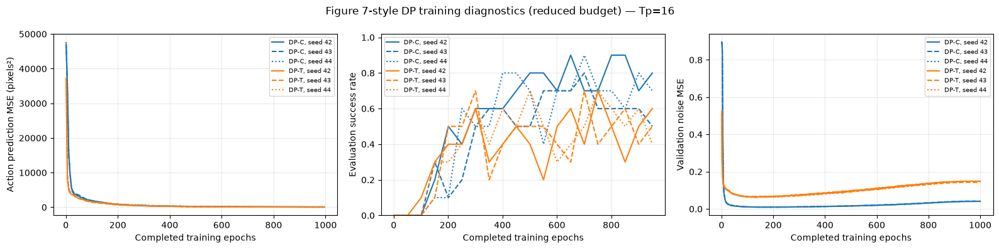

In [ ]:
from pathlib import Path
import csv
import json
import numpy as np
import matplotlib.pyplot as plt

def read_history(folder):
    """Read the per-epoch measurements for one training run."""
    history_path = folder / 'history.json'
    if not history_path.exists():
        return []
    return json.loads(history_path.read_text())


def completed_job(folder):
    """Check whether a run's status file marks its training as complete."""
    status_path = folder / 'status.json'
    if not status_path.exists():
        return False
    status = json.loads(status_path.read_text())
    return status.get('complete', False)


def display_results_table(rows):
    """Display a list of dictionaries as a plain-text table."""
    if not rows:
        print('No results yet.')
        return

    # Dictionary keys become column headings
    column_names = list(rows[0])
    text_rows = [column_names]
    for record in rows:
        text_rows.append([str(record.get(name, '')) for name in column_names])

    # to make each column wide enough
    column_widths = [
        max(len(row[column]) for row in text_rows)
        for column in range(len(column_names))
    ]
    for row_number, row in enumerate(text_rows):
        print(' | '.join(
            value.ljust(width) for value, width in zip(row, column_widths)
        ))
        if row_number == 0:
            print('-+-'.join('-' * width for width in column_widths))


def save_results_csv(rows, path):
    """Save the table so it can also be opened in a spreadsheet application."""
    if not rows:
        return
    with path.open('w', newline='') as stream:
        writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)


# uses the same settings and output folders as the preceding training cells.
required_settings = ['RUN_DIR', 'RESULT_DIR', 'MODE', 'TRAIN_SEEDS', 'HORIZONS', 'TRAIN_EPOCHS', 'EVALUATION_EPISODES']
missing_settings = [name for name in required_settings if name not in globals()]

if missing_settings:
    raise RuntimeError(
        'Run the notebook setup first. Missing settings: ' + ', '.join(missing_settings)
    )

is_smoke_test = MODE == 'smoke'
training_seeds = [42] if is_smoke_test else TRAIN_SEEDS
prediction_horizons = HORIZONS
training_epochs = 2 if is_smoke_test else TRAIN_EPOCHS
evaluation_episodes = 2 if is_smoke_test else EVALUATION_EPISODES
output_directory = Path(RESULT_DIR)
output_directory.mkdir(parents=True, exist_ok=True)
experiment_runs = {}

for prediction_horizon in prediction_horizons:
    for model_type in ['DP-C', 'DP-T']:
        for training_seed in training_seeds:
            run_name = f'{model_type}_seed{training_seed}_Tp{prediction_horizon}'
            run_folder = Path(RUN_DIR) / run_name
            if not (run_folder / 'history.json').exists():
                raise FileNotFoundError(
                    f'Missing training history: {run_folder / "history.json"}. '
                    'Run training first, or restore the saved experiment files.'
                )
            experiment_runs[run_name] = {
                'history': read_history(run_folder),
                'status': {'complete': completed_job(run_folder)}
            }


# summarizes each training run separately.
checkpoint_rows = []
for prediction_horizon in prediction_horizons:
    for model_type in ['DP-C', 'DP-T']:
        for training_seed in training_seeds:
            run_name = f'{model_type}_seed{training_seed}_Tp{prediction_horizon}'
            run_records = experiment_runs[run_name]
            training_history = run_records['history']

            # Simulation scores are recorded periodically, not every epoch.
            evaluated_checkpoints = [
                record for record in training_history
                if record.get('mean_peak_score') is not None
            ]
            coverage_scores = [
                record['mean_peak_score'] for record in evaluated_checkpoints
            ]
            summary = {
                'model': model_type,
                'train_seed': training_seed,
                'prediction_horizon': prediction_horizon,
                'completed_epochs': training_history[-1]['epoch'] if training_history else 0,
                'target_epochs': training_epochs,
                'evaluated_checkpoints': len(evaluated_checkpoints),
                'complete': run_records['status'].get('complete', False),
                'max_score': max(coverage_scores, default=None),
                'mean_last10': None,
                'mean_10_lowest_training_loss': None
            }

            if len(evaluated_checkpoints) >= 10:
                # Last ten EVALUATED checkpoints, not the last ten epochs.
                last_ten = evaluated_checkpoints[-10:]
                summary['mean_last10'] = float(np.mean([
                    record['mean_peak_score'] for record in last_ten
                ]))

                # Separate diagnostic: among evaluated checkpoints, select
                # the ten with lowest training loss, then average their scores.
                lowest_loss_checkpoints = sorted(
                    evaluated_checkpoints,
                    key=lambda record: record['train_noise_mse']
                )[:10]
                summary['mean_10_lowest_training_loss'] = float(np.mean([
                    record['mean_peak_score'] for record in lowest_loss_checkpoints
                ]))
            checkpoint_rows.append(summary)

display_results_table(checkpoint_rows)
save_results_csv(checkpoint_rows, output_directory / 'checkpoint_summary.csv')


# Table I - comparison that combines the three seeds for each architecture.
table1 = []
for model_type in ['DP-C', 'DP-T']:
    model_rows = [
        row for row in checkpoint_rows
        if row['model'] == model_type and row['prediction_horizon'] == 16
    ]
    experiment_complete = (
        len(model_rows) == 3
        and all(row['complete'] and row['mean_last10'] is not None for row in model_rows)
        and not is_smoke_test
    )
    scored_runs = [row for row in model_rows if row['max_score'] is not None]
    runs_with_last_ten = [row for row in model_rows if row['mean_last10'] is not None]
    best_scores = [row['max_score'] for row in scored_runs]

    mean_best_score = float(np.mean(best_scores)) if best_scores else None
    # ddof=1 gives sample SD across training-seed maxima, not across episodes.
    best_score_std = float(np.std(best_scores, ddof=1)) if len(best_scores) > 1 else None
    mean_last_ten = None
    if runs_with_last_ten and len(runs_with_last_ten) == len(model_rows):
        mean_last_ten = float(np.mean([
            row['mean_last10'] for row in runs_with_last_ten
        ]))

    table1.append({
        'model': model_type,
        'status': ('COMPLETE reduced-budget keypoint experiment'
                   if experiment_complete else 'PRELIMINARY / INCOMPLETE'),
        'training_seeds_with_scores': len(scored_runs),
        'training_epochs_per_run': training_epochs,
        'evaluation_episodes_per_checkpoint': evaluation_episodes,
        'mean_max': mean_best_score,
        'std_across_seed_maxima': best_score_std,
        'mean_last10': mean_last_ten,
        # Published references; our training and evaluation budgets differ.
        'paper_keypoint_max_reference': .95,
        'paper_keypoint_last10_reference': .91 if model_type == 'DP-C' else .79
    })

print('\nTable I-style comparison: reduced budget; checkpoint selection reused evaluation seeds.')
display_results_table(table1)
save_results_csv(table1, output_directory / 'table1_baseline.csv')


# Figure 7 - one curve per model and training seed.
plot_metrics = [
    ('action_mse', 'Action prediction MSE (pixels²)'),
    ('success_rate', 'Evaluation success rate'),
    ('validation_noise_mse', 'Validation noise MSE')
]
model_colors = [('DP-C', 'tab:blue'), ('DP-T', 'tab:orange')]
line_styles = ['-', '--', ':']

for prediction_horizon in prediction_horizons:
    figure, axes = plt.subplots(1, 3, figsize=(16, 4))
    has_measurements = False

    for model_type, color in model_colors:

        for seed_index, training_seed in enumerate(training_seeds):
            run_name = f'{model_type}_seed{training_seed}_Tp{prediction_horizon}'
            training_history = experiment_runs[run_name]['history']
            line_style = line_styles[seed_index % len(line_styles)]

            # Pair each subplot with its metric name and axis label.
            for axis, (metric_name, axis_label) in zip(axes, plot_metrics):
                available_records = [
                    record for record in training_history
                    if record.get(metric_name) is not None
                ]
                if available_records:
                    has_measurements = True
                    epochs = [record['epoch'] for record in available_records]
                    measurements = [record[metric_name] for record in available_records]
                    axis.plot(
                        epochs, measurements, color=color, linestyle=line_style,
                        label=f'{model_type}, seed {training_seed}'
                    )
                axis.set_xlabel('Completed training epochs')
                axis.set_ylabel(axis_label)
                axis.grid(alpha=.25)

    if has_measurements:

        for axis in axes:
            axis.legend(fontsize=7)

        # Success rate is between 0 and 1, 1.02 used for a small margin above 1.0 to avoid clipping the top of the plot.
        axes[1].set_ylim(0, 1.02)

        title_prefix = 'SMOKE — no performance conclusions; ' if is_smoke_test else ''
        figure.suptitle(
            title_prefix + 'Figure 7-style DP training diagnostics (reduced budget) '
            f'— Tp={prediction_horizon}'
        )
        figure.tight_layout()
        figure.savefig(output_directory / f'figure7_Tp{prediction_horizon}.png', dpi=170)
        figure.savefig(output_directory / f'figure7_Tp{prediction_horizon}.pdf')
        plt.show()

    else:
        plt.close(figure)

print('Regenerated tables and figures saved to:', output_directory)


## 13. Figure 6-style ablations
I used the same trained 16-step models at Ta 1/2/4/8/15. 
The authors' complete Figure 6 overrides were unavailable so I could not test Ta 16 – 128 with the models.

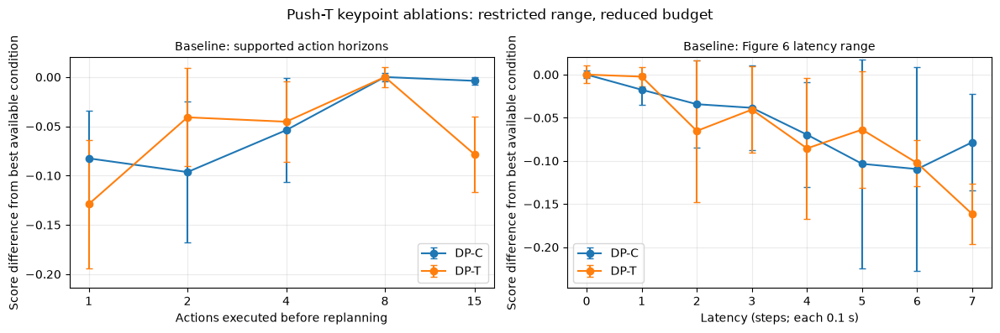

In [ ]:
def cached_evaluation(folder, model, saved, ta, delay, seeds):

    name=f'{LATENCY_PROTOCOL}_epoch{saved["epoch"]}_Ta{ta}_delay{delay}'
    path=folder/'evaluation_cache'/f'{name}.json'
    cache=json.loads(path.read_text()) if path.exists() else {'signature':saved['signature'],'episodes':[]}

    if cache['signature']!=saved['signature']:
        raise ValueError('Evaluation cache signature mismatch.')
    
    done={r['environment_seed'] for r in cache['episodes']}
    todo=[s for s in seeds if s not in done]

    for start in range(0,len(todo),EVAL_BATCH_SIZE):
        subset=todo[start:start+EVAL_BATCH_SIZE]
        rows,_=evaluate_rollouts(model,saved['spec']['kind'],saved['spec'],subset,ta,delay, max_steps=saved['spec']['max_episode_steps'])
        cache['episodes'].extend(rows);atomic_json(cache,path)
        
    requested={int(s) for s in seeds}
    return [r for r in cache['episodes'] if r['environment_seed'] in requested]


ablation_rows=[]
for kind,seed,horizon in JOBS:

    folder=RUN_DIR/job_name(kind,seed,horizon)

    if not completed_job(folder) or not (folder/'best.pt').exists():
        continue

    model,saved=load_best(folder)

    action_values=[1,2,4,8,15]
    conditions=[('action_horizon',ta,0) for ta in action_values]

    if horizon==16:
        conditions += [('latency',8,d) for d in range(8)]

    for study,ta,delay in conditions:
        rows=cached_evaluation(folder,model,saved,ta,delay,saved['spec']['test_seeds'])
        if rows is None:break
        ablation_rows.append({'model':kind,'train_seed':seed,'Tp':horizon,'study':study,'action_horizon':ta,'latency_steps':delay,'selected_epoch':saved['epoch'], **score_summary(rows)})
    del model
    if DEVICE.type=='cuda':torch.cuda.empty_cache()
save_csv(ablation_rows,RESULT_DIR/'ablation_per_training_seed.csv')


def aggregate_ablation(rows, study, horizon):

    grouped={}
    xname='action_horizon' if study=='action_horizon' else 'latency_steps'

    for row in rows:
        if row['study']!=study or row['Tp']!=horizon:continue
        grouped.setdefault((row['model'],row[xname]),[]).append(row)

    result=[]

    for (kind,x),group in sorted(grouped.items()):
        scores=[r['mean_peak_score'] for r in group]
        result.append({'model':kind,'study':study,'Tp':horizon,xname:x, 'mean_score':float(np.mean(scores)),
                       'std_across_training_seeds':float(np.std(scores,ddof=1)) if len(scores)>1 else 0., 'n_training_seeds':len(scores)})
        
    for kind in ['DP-C','DP-T']:
        subset=[r for r in result if r['model']==kind]

        if subset:
            best=max(r['mean_score'] for r in subset)
            for r in subset:r['difference_from_best']=r['mean_score']-best

    return result


aggregated=[]

for study,horizon in [('action_horizon',16),('latency',16)]:
    aggregated.extend(aggregate_ablation(ablation_rows,study,horizon))

save_csv(aggregated,RESULT_DIR/'ablation_aggregates.csv')

if aggregated:
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    configs=[('action_horizon',16,'Baseline: supported action horizons'),
             ('latency',16,'Baseline: Figure 6 latency range')]
    for ax,(study,horizon,title) in zip(axes,configs):

        xname='action_horizon' if study=='action_horizon' else 'latency_steps'
        for kind,color in [('DP-C','tab:blue'),('DP-T','tab:orange')]:

            rows=sorted([r for r in aggregated if r['study']==study and r['Tp']==horizon and r['model']==kind],key=lambda r:r[xname])
            if not rows:continue
            xs=[r[xname] for r in rows];ys=[r['difference_from_best'] for r in rows]
            ax.errorbar(xs,ys,yerr=[r['std_across_training_seeds'] for r in rows],fmt='o-',capsize=3,label=kind,color=color)

        if study=='action_horizon':
            ticks=[1,2,4,8,15]
            ax.set_xscale('log',base=2);ax.set_xticks(ticks,labels=[str(x) for x in ticks])
            ax.set_xlabel('Actions executed before replanning')

        else:
            ax.set_xticks(range(8));ax.set_xlabel('Latency (steps; each 0.1 s)')

        plotted=[float(y) for line in ax.lines for y in line.get_ydata()]
        ax.set_ylim(min(-0.05, min(plotted,default=0.)-0.02),0.02)
        ax.set_title(title,fontsize=10);ax.set_ylabel('Score difference from best available condition')
        ax.grid(alpha=.25)
    
        if ax.lines:ax.legend()

    fig.suptitle('SMOKE — no performance conclusions' if MODE=='smoke' else 'Push-T keypoint ablations: restricted range, reduced budget')
    fig.tight_layout();fig.savefig(RESULT_DIR/'figure6_ablations.png',dpi=170)
    fig.savefig(RESULT_DIR/'figure6_ablations.pdf');plt.show()

else:
    print('Ablations wait for completed jobs and their best checkpoints.')

## 14. Five seeded environments
The same five predeclared random initial states are shown for both architectures. They use training seed 42, and they are chosen before observing performance.

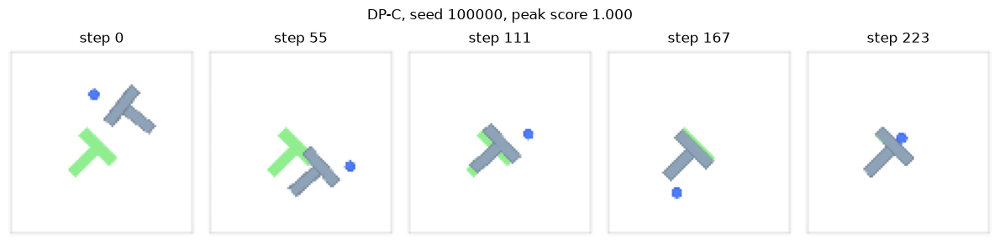

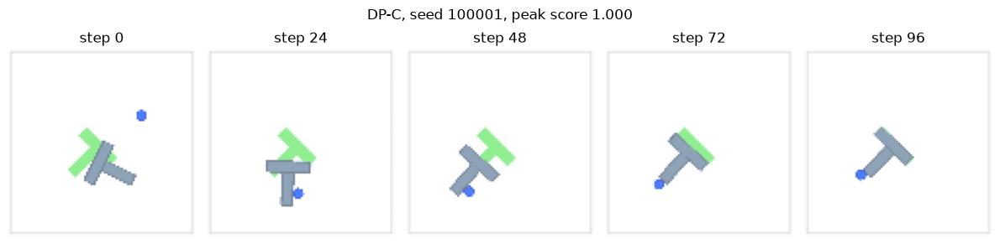

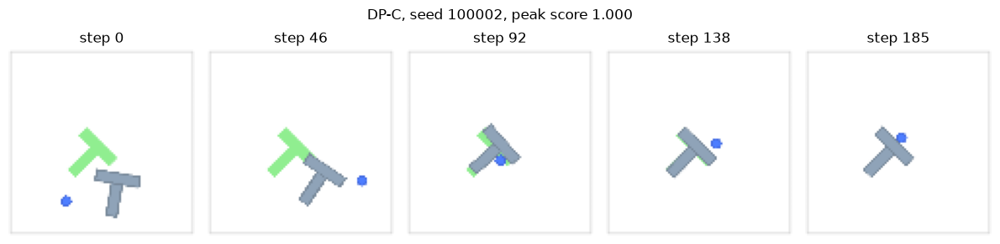

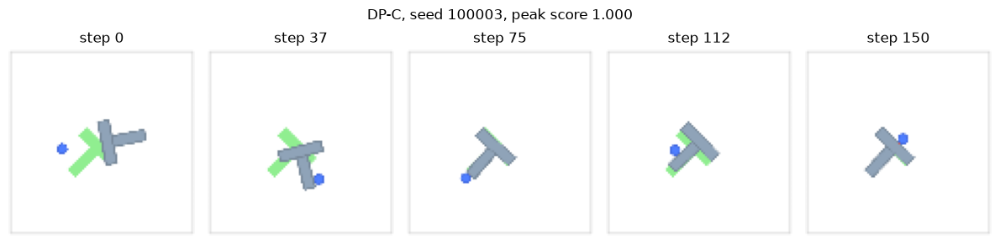

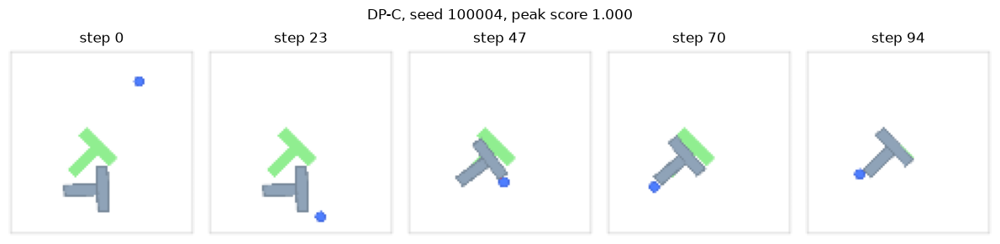

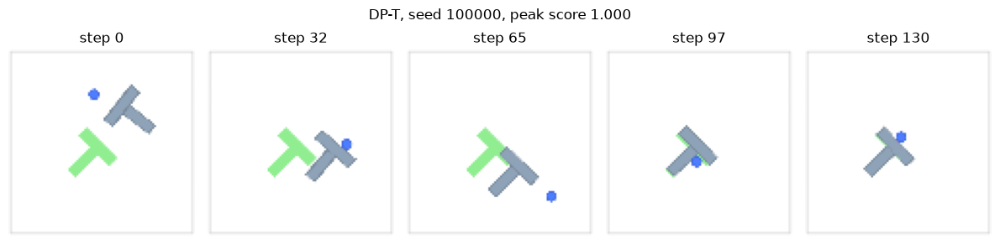

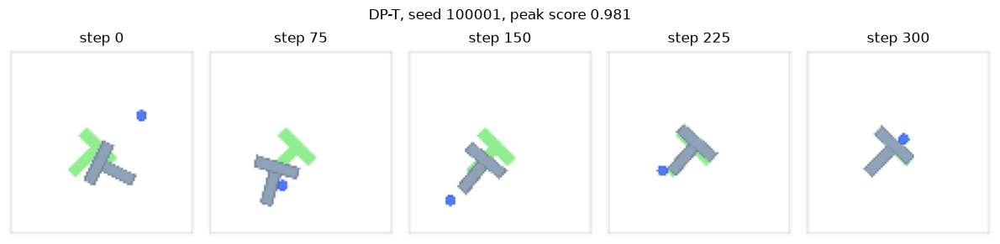

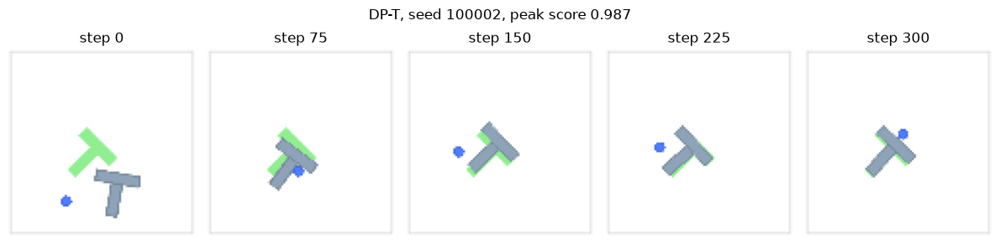

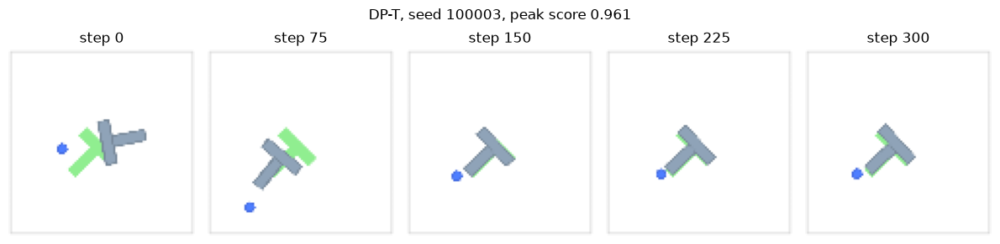

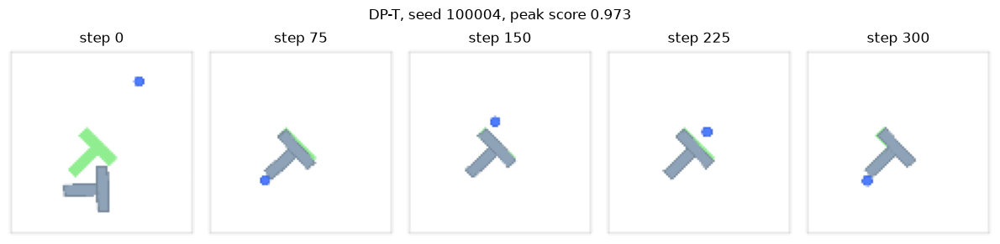

Saved visualizations: 10 / 10 (five environments for each of DP-C and DP-T).


In [ ]:
VISUAL_SEEDS=[100000,100001,100002,100003,100004]

visual_rows=[]

for kind in ['DP-C','DP-T']:

    folder=RUN_DIR/job_name(kind,42,16)

    if not completed_job(folder) or not (folder/'best.pt').exists():continue
    model,saved=load_best(folder)
    video_dir=RESULT_DIR/'five_seed_rollouts'/f'{kind}_epoch{saved["epoch"]}'
    video_dir.mkdir(parents=True,exist_ok=True)

    for seed in VISUAL_SEEDS:
        receipt=video_dir/f'seed{seed}.json'
        if receipt.exists():
            cached=json.loads(receipt.read_text())

            if cached.get('signature')==saved['signature'] and (video_dir/f'seed{seed}.html').exists():
                display(HTML((video_dir/f'seed{seed}.html').read_text()))
                visual_rows.append(cached['metrics']);continue
            
        rows,recordings=evaluate_rollouts(model,kind,saved['spec'],[seed],record=True, max_steps=saved['spec']['max_episode_steps'])
        trace=recordings[seed]
        np.savez_compressed(video_dir/f'seed{seed}.npz',states=np.asarray(trace['states']),
                            actions=np.asarray(trace['actions']),scores=np.asarray(trace['rewards']),
                            coverage=np.asarray(trace['coverage']))
        
        frames=trace['frames']
        fig,ax=plt.subplots(figsize=(4,4));ax.axis('off')
        picture=ax.imshow(frames[0]);ax.set_title(f'{kind}: seed {seed}')

        def update_frame(index):
            picture.set_data(frames[index]);return (picture,)
        
        movie=animation.FuncAnimation(fig,update_frame,frames=len(frames),interval=100,blit=True)

        html_video=movie.to_jshtml(fps=10);plt.close(fig)

        (video_dir/f'seed{seed}.html').write_text(html_video)
        display(HTML(html_video))

        fig,axes=plt.subplots(1,5,figsize=(12,3))

        for ax,frame in zip(axes,np.linspace(0,len(frames)-1,5,dtype=int)):
            ax.imshow(frames[frame]);ax.set_title(f'step {frame}');ax.axis('off')
        fig.suptitle(f'{kind}, seed {seed}, peak score {rows[0]["peak_score"]:.3f}'+ (' — SMOKE' if MODE=='smoke' else ''))
        fig.tight_layout();fig.savefig(video_dir/f'seed{seed}.png',dpi=160);plt.show()
        metric={'model':kind,'train_seed':42,'selected_epoch':saved['epoch'],**rows[0]}
        atomic_json({'signature':saved['signature'],'metrics':metric},receipt)
        visual_rows.append(metric)
        
    del model
    if DEVICE.type=='cuda':torch.cuda.empty_cache()

save_csv(visual_rows,RESULT_DIR/'five_seed_rollout_metrics.csv')
print('Saved visualizations:',len(visual_rows),'/ 10 (five environments for each of DP-C and DP-T).')